# NGC4654 local rSFMS excess and VIVA sector

This section repeats the projected Fourier analysis from [the NGC4654 excess notebook](20261015_check_NGC4654_rSFMS_excess_Fourier_local_enhancement.ipynb) using the Paper II SF selection, equal-galaxy pre-peak rSFMS, and width \(W\) from the Paper II excess analysis. This standalone extraction of [the Paper II notebook](20261021_plot_paper_2.ipynb) recomputes the reference relation and width from the eligible pre-peak galaxies. NGC4654 is the only mapped galaxy. Run the cells from top to bottom; the VIVA map is displayed inline. The map shows \(E=(\log\Sigma_{\rm SFR}-\log\Sigma_{\rm SFR,ref})/W\) over the full selected SF footprint.

$$
\begin{aligned}
\widehat E_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{c_1\cos\phi_i+s_1\sin\phi_i}_{m=1}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

Here \(i\) indexes a continuum bin, \(a\) is its annulus, \(r_i=R_i/R_e\), \(r_a\) is the annulus midpoint, and \(\phi_i\) is the bin's sky PA measured east of north. The shared \(m=1\) coefficients give \(A=\sqrt{c_1^2+s_1^2}\) and \(\theta=\operatorname{atan2}(s_1,c_1)\) modulo \(360^\circ\). Setting \(c_1=s_1=0\) and refitting the annular coefficients gives the comparison model without \(m=1\).

The fitted arrow gives the projected sky phase of the shared \(m=1\) term. The fit uses four annuli of width \(0.4R_e\) over \(0 \le R/R_e \le 1.6\), with an intercept, radial slope and \(m=2\) pair per populated annulus. Spaxel counts, BINID counts and azimuthal coverage are reported as diagnostics. Each continuum BINID contributes one observation. Its centre is the geometric centroid of all native spaxels with that BINID in the tangent plane. Its excess is the mean \(E\) of its selected SF spaxels. The radial cut applies to the centroid. The arrow maps show native spaxels. The heatmaps, angular residual panels, and cell 9 use the bin means at their centroids. Uncertainty and the incremental \(m=1\) test use the reference notebook's whole-BINID bootstrap and restricted wild bootstrap.

The VIVA overlay is the coarse northwest compass sector (PA \(270^\circ\)–\(360^\circ\), east of north). It represents the adopted environmental context of the reference plot.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8_7000'
SNR_POSTFIT_MIN = 25.0  # STRICT common cut before any local SF/NSF/ND classification
INCLINATION_MAX = 80.0  # STRICT galaxy cut for the entire notebook
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
PAIR_PRODUCT_ID = 'NGC4567_8'
PAIR_SEGMENTATION_PATH = PROJECT_ROOT / 'NGC4567_8_photometric_segmentation_7000.fits'
PAIR_COMPONENT_LABELS = {'NGC4567': 1, 'NGC4568': 2}

NGC4654_FIT_EDGES = np.linspace(0.0, 1.6, 5)

EW_MIN = 6.0
SIGMA_MAX = 45.0  # intrinsic Halpha sigma; strict upper bound

mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 22, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def first_product_existing(product_id, names):
    for folder_suffix in ('', '_SFH16'):
        folder = DATA_ROOT / f'{product_id}{folder_suffix}'
        prefixes = (product_id, f'{product_id}{folder_suffix}')
        candidates = [f'{prefix}_{name}' for prefix in prefixes for name in names]
        found = first_existing(folder, candidates)
        if found is not None:
            return found
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component):
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    east, north = tangent_offsets_arcsec(
        ra, dec, component.center_ra_deg, component.center_dec_deg
    )
    return elliptical_radius_from_offsets(east, north, component)


def elliptical_radius_from_offsets(east, north, component):
    pa = np.deg2rad(float(component.pa_deg_east_of_north))
    major = east * np.sin(pa) + north * np.cos(pa)
    minor = east * np.cos(pa) - north * np.sin(pa)
    return np.sqrt((major / float(component.a_re_arcsec)) ** 2
                   + (minor / float(component.b_re_arcsec)) ** 2)


def galaxy_footprint(product_id, galaxy, shape, header):
    if product_id != PAIR_PRODUCT_ID:
        return True
    labels, label_header = read_map(PAIR_SEGMENTATION_PATH, 0)
    if labels.shape != shape:
        raise ValueError(f'{PAIR_PRODUCT_ID}: segmentation and science-map shapes differ')
    check_wcs(header, label_header, shape, f'{PAIR_PRODUCT_ID} mass/segmentation')
    if not np.all(np.isnan(labels) | np.isin(labels, (0, *PAIR_COMPONENT_LABELS.values()))):
        raise ValueError(f'{PAIR_SEGMENTATION_PATH}: unexpected segmentation labels')
    return labels == PAIR_COMPONENT_LABELS[galaxy]


def apply_component_inclination(product_id, component, mass, gas_arrays):
    if product_id != PAIR_PRODUCT_ID:
        return
    # The current combined products store projected densities (b/a = 1).
    q0 = float(component.intrinsic_axis_ratio_q0)
    cos_i = np.cos(np.deg2rad(float(component.inclination_deg)))
    b_over_a = np.sqrt((1 - q0**2) * cos_i**2 + q0**2)
    delta = float(np.log10(b_over_a))
    mass += delta
    gas_arrays['LOGSFR_SURFACE_DENSITY_HII'] += delta


# The product ID locates FITS files; the galaxy ID determines geometry and statistics.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip(): int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int), geometry.mauve_infall_stage.astype(int))
geometry_by_galaxy = geometry.set_index('galaxy', verify_integrity=True)
product_components = {
    product_id: tuple(components.galaxy)
    for product_id, components in geometry.groupby('notebook_product_id')
}


In [3]:
# Only load the pre-peak reference sample and the NGC4654 target.
def iter_galaxy_inputs():
    product_ids = sorted({
        folder.name.removesuffix('_SFH16')
        for folder in DATA_ROOT.iterdir()
        if folder.is_dir() and not folder.name.endswith('_logs')
    })
    for product_id in product_ids:
        components = product_components[product_id]
        expected = set(PAIR_COMPONENT_LABELS) if product_id == PAIR_PRODUCT_ID else {product_id}
        if set(components) != expected:
            raise ValueError(f'{product_id}: unexpected geometry components {components}')
        if all(geometry_by_galaxy.loc[g, 'stage_code'] != 1 and g != 'NGC4654' for g in components):
            continue
        paths = {
            'mass': first_product_existing(product_id, ['spatial_binning_maps_further.fits',
                                                        'SPATIAL_BINNING_maps_further.fits']),
            'gas': first_product_existing(product_id, ['gas_bin_maps_further.fits',
                                                       'gas_BIN_maps_further.fits']),
            'ew': first_product_existing(product_id, ['proxy_EW_maps_further.fits',
                                                      'proxy_EW_maps.fits']),
            'sfh': first_product_existing(product_id, ['sfh_maps.fits']),
            'mask': first_product_existing(product_id, ['mask.fits']),
        }
        for galaxy in sorted(components):
            component = geometry_by_galaxy.loc[galaxy]
            inclination = float(component.inclination_deg)
            if component.stage_code != 1 and galaxy != 'NGC4654':
                continue
            meta = dict(stage=int(component.stage_code), inclination=inclination,
                        inclination_ok=bool(np.isfinite(inclination) and inclination < INCLINATION_MAX))
            yield product_id, galaxy, component, meta, paths

sf_x_parts, sf_y_parts, sf_group_parts, sf_error_parts = [], [], [], []
inventory_rows, count_rows = [], []
ngc4654_sf_geometry = None
ngc4654_bin_geometry = None
ngc4654_native_binid = None
for product_id, gal, component, meta, paths in iter_galaxy_inputs():
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,product_id=product_id,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))
    if not meta['inclination_ok'] or missing:
        continue
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR',
            'HA6562_FLUX_CORR', 'HA6562_FLUX_ERR_CORR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    apply_component_inclination(product_id, component, mass, arrays)
    footprint = galaxy_footprint(product_id, gal, mass.shape, mass_hdr)
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0) & footprint
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    sigma = np.sqrt(np.where(np.isfinite(sigma2) & (sigma2 > 0), sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(sigma) & (sigma < SIGMA_MAX)
    assert not np.any(sf & ~balmer), f'{gal}: SF overlaps Balmer ND'
    group_id = len(count_rows)
    sf_x_parts.append(mass[sf])
    sf_y_parts.append(sfr[sf])
    sf_group_parts.append(np.full(int(sf.sum()), group_id, dtype=np.int16))
    if gal == 'NGC4654':
        radius_re = calculate_deprojected_radius(mass.shape, mass_hdr, component)
        assert np.isfinite(radius_re[valid]).all(), f'{gal}: nonfinite R/Re in the common usable mask'
        continuum_binid, binid_hdr = read_map(paths['mass'], 'BINID')
        if continuum_binid.shape != sf.shape:
            raise ValueError(f'{gal}: continuum BINID and SF mask shapes differ')
        check_wcs(mass_hdr, binid_hdr, sf.shape, f'{gal} mass/continuum BINID')
        pixel_y, pixel_x = np.nonzero(sf)
        ra, dec = WCS(mass_hdr).celestial.pixel_to_world_values(pixel_x, pixel_y)
        east, north = tangent_offsets_arcsec(ra, dec, component.center_ra_deg, component.center_dec_deg)
        ngc4654_sf_geometry = pd.DataFrame(dict(east=east, north=north,
            r=radius_re[sf], binid=continuum_binid[sf]), index=np.flatnonzero(sf))
        # Use every native pixel in each continuum BINID, including non-SF pixels.
        native = (np.isfinite(continuum_binid) & (continuum_binid >= 0)
                  & (continuum_binid == np.floor(continuum_binid)))
        native_y, native_x = np.nonzero(native)
        native_ra, native_dec = WCS(mass_hdr).celestial.pixel_to_world_values(native_x, native_y)
        native_east, native_north = tangent_offsets_arcsec(
            native_ra, native_dec, component.center_ra_deg, component.center_dec_deg)
        bin_ids, bin_index, bin_count = np.unique(
            continuum_binid[native].astype(np.int64), return_inverse=True, return_counts=True)
        centre_east = np.bincount(bin_index, weights=native_east) / bin_count
        centre_north = np.bincount(bin_index, weights=native_north) / bin_count
        ngc4654_bin_geometry = pd.DataFrame(dict(
            binid=bin_ids, east=centre_east, north=centre_north, N_native=bin_count,
            r=elliptical_radius_from_offsets(centre_east, centre_north, component)))
        ngc4654_native_binid = continuum_binid
    # Paired Halpha errors for the source excess-width recipe, in the same SF order.
    ha_flux_sf = arrays['HA6562_FLUX_CORR'][sf]
    ha_error_sf = arrays['HA6562_FLUX_ERR_CORR'][sf]
    ha_error_ok = np.isfinite(ha_flux_sf) & (ha_flux_sf > 0) & np.isfinite(ha_error_sf) & (ha_error_sf >= 0)
    sf_error_dex = np.full(len(ha_flux_sf), np.nan)
    sf_error_dex[ha_error_ok] = ha_error_sf[ha_error_ok] / ha_flux_sf[ha_error_ok] / np.log(10.0)
    sf_error_parts.append(sf_error_dex)
    count_rows.append(dict(galaxy=gal, stage=meta['stage'], inclination=meta['inclination'],
                           usable=int(valid.sum()), SF=int(sf.sum())))

if not count_rows:
    raise RuntimeError('No complete Paper II product sets found for NGC4654 or the pre-peak reference')
inventory = pd.DataFrame(inventory_rows)
counts = pd.DataFrame(count_rows)
sf_x, sf_y, sf_group = (np.concatenate(parts) for parts in (sf_x_parts, sf_y_parts, sf_group_parts))
assert sf_x.size == sf_y.size == sf_group.size == counts.SF.sum()
display(inventory[['galaxy', 'product_id', 'stage', 'inclination', 'status']])
display(counts)

,galaxy,product_id,stage,inclination,status
0,NGC4189,NGC4189,1,42.0,included
1,NGC4192,NGC4192,1,83.0,excluded: inclination >=80 or unavailable
2,NGC4222,NGC4222,1,90.0,excluded: inclination >=80 or unavailable
3,NGC4254,NGC4254,1,39.0,included
4,NGC4294,NGC4294,1,74.0,included
5,NGC4321,NGC4321,1,32.0,included
6,NGC4351,NGC4351,1,48.0,included
7,NGC4383,NGC4383,1,56.0,included
8,NGC4396,NGC4396,1,83.0,excluded: inclination >=80 or unavailable
9,NGC4535,NGC4535,1,48.0,included


,galaxy,stage,inclination,usable,SF
0,NGC4189,1,42.0,134346,88582
1,NGC4254,1,39.0,615883,453580
2,NGC4294,1,74.0,125185,66537
3,NGC4321,1,32.0,808599,382821
4,NGC4351,1,48.0,98128,29767
5,NGC4383,1,56.0,62174,15627
6,NGC4535,1,48.0,459337,161648
7,NGC4567,1,49.0,175337,87590
8,NGC4568,1,70.0,218439,114364
9,NGC4654,2,61.0,555079,325678


In [4]:
def equal_galaxy_ols(x, y, group):
    """Minimize sum_g mean_g[(y-alpha*x-beta)**2]; weight per pixel = 1/N_g."""
    x, y, group = np.asarray(x), np.asarray(y), np.asarray(group)
    assert len(x) == len(y) == len(group) and len(x) > 2
    assert np.isfinite(x).all() and np.isfinite(y).all() and (group >= 0).all()
    # Exact weighted moments; no per-spaxel design matrix or variance weighting.
    count = np.bincount(group)
    active = count > 0
    gx = np.bincount(group,weights=x)[active]/count[active]
    gy = np.bincount(group,weights=y)[active]/count[active]
    gxx = np.bincount(group,weights=x*x)[active]/count[active]
    gxy = np.bincount(group,weights=x*y)[active]/count[active]
    mx, my = gx.mean(), gy.mean()
    variance_x = gxx.mean()-mx**2
    assert variance_x > 0
    slope = (gxy.mean()-mx*my)/variance_x
    intercept = my-slope*mx
    # Weighted residual normal equations must vanish for the OLS solution.
    assert np.isclose((gy-slope*gx-intercept).mean(),0,atol=1e-9)
    assert np.isclose((gxy-slope*gxx-intercept*gx).mean(),0,atol=1e-8)
    return dict(slope=float(slope),intercept=float(intercept),n_spaxels=len(x),
        n_groups=int(active.sum()),xmin=float(x.min()),xmax=float(x.max()),
        group_ids=np.flatnonzero(active),group_counts=count[active])

sf_stage = counts.stage.to_numpy(int)[sf_group]
assert (sf_stage == 1).any(), 'No pre-peak SF reference products'
pre=sf_stage==1
pre_peak_fit=equal_galaxy_ols(sf_x[pre],sf_y[pre],sf_group[pre])

assert counts.inclination.lt(INCLINATION_MAX).all()
excess_meta = counts.reset_index(drop=True)
target = excess_meta.loc[excess_meta.galaxy.eq('NGC4654')]
if len(target) != 1 or int(target.iloc[0].SF) == 0:
    raise ValueError('NGC4654: not available with SF spaxels after the global cuts; inspect inventory')
assert int(target.iloc[0].stage) == 2, 'NGC4654: unexpected catalogue stage'
excess_errors = np.concatenate(sf_error_parts)
assert len(excess_errors) == len(sf_x) == len(sf_y) == len(sf_group)
excess_reference = pre_peak_fit['slope'] * sf_x + pre_peak_fit['intercept']
excess_residuals = sf_y - excess_reference
excess_pre_ids = excess_meta.index[(excess_meta.stage == 1) & (excess_meta.SF > 0)].to_numpy()
assert len(excess_pre_ids), 'No pre-peak SF reference products'
excess_width_rows = []
for group_id in excess_pre_ids:
    selected = (sf_group == group_id) & np.isfinite(excess_errors) & (excess_errors >= 0)
    assert selected.any(), f'{excess_meta.loc[group_id, "galaxy"]}: no finite errors for width'
    radicand = excess_residuals[selected]**2 - excess_errors[selected]**2
    excess_width_rows.append(dict(galaxy=excess_meta.loc[group_id, 'galaxy'],
        N_width=int(selected.sum()), width_dex=float(np.sqrt(np.maximum(radicand, 0)).mean()),
        fraction_clipped_to_zero=float((radicand <= 0).mean())))
excess_width_by_galaxy = pd.DataFrame(excess_width_rows)
excess_width = float(excess_width_by_galaxy.width_dex.mean())
assert np.isfinite(excess_width) and excess_width > 0
excess_values = excess_residuals / excess_width

display(excess_width_by_galaxy)
print(f'Pre-peak equal-galaxy reference: y={pre_peak_fit["slope"]:.6f}x{pre_peak_fit["intercept"]:+.6f}; W={excess_width:.6f} dex')

,galaxy,N_width,width_dex,fraction_clipped_to_zero
0,NGC4189,88582,0.359797,0.027974
1,NGC4254,453580,0.447343,0.028438
2,NGC4294,66537,0.357248,0.014188
3,NGC4321,382821,0.389444,0.029442
4,NGC4351,29767,0.366184,0.017402
5,NGC4383,15627,0.444388,0.018878
6,NGC4535,161648,0.464960,0.016307
7,NGC4567,87590,0.335900,0.039034
8,NGC4568,114364,0.358164,0.042076


Pre-peak equal-galaxy reference: y=0.748260x-7.992286; W=0.391492 dex


In [5]:
from scipy.optimize import least_squares

def fit_ngc4654_excess(frame):
    # Fourier model and BINID resampling from the reference notebook.
    edges = NGC4654_FIT_EDGES
    centers = (edges[:-1] + edges[1:]) / 2
    MIN_BINS_FIT = 20
    MAX_DESIGN_CONDITION = 1e6
    frame = frame.copy()
    frame['theta'] = np.where(np.hypot(frame.east, frame.north) > 0,
        np.arctan2(frame.east, frame.north) % (2 * np.pi), np.nan)
    valid = (np.isfinite(frame.binid) & (frame.binid >= 0)
             & (frame.binid == np.floor(frame.binid))
             & np.isfinite(frame.theta) & frame.r.between(edges[0], edges[-1]))
    native = frame.loc[valid].copy()
    if native.empty:
        raise ValueError(f'NGC4654: no continuum bins with SF excess and valid sky angles within {edges[-1]:g} Re')
    native['binid'] = native.binid.astype(np.int64)
    # Include the outer endpoint in the final annulus.
    native['annulus'] = np.minimum(
        np.searchsorted(edges, native.r, side='right') - 1, len(centers) - 1)
    coverage_rows = []
    for annulus, bins in native.groupby('annulus'):
        sectors = np.floor(bins.theta.to_numpy() / (2 * np.pi) * 12)
        coverage_rows.append(dict(annulus=annulus, N_SF=int(bins.N_SF.sum()),
                                  N_BINID=len(bins), sectors=np.unique(sectors).size))
    coverage = pd.DataFrame(coverage_rows)

    def native_design(frame, annuli):
        cols=[]
        for a in annuli:
            take=frame.annulus.eq(a).to_numpy(float)
            cols.extend([take,take*(frame.r.to_numpy()-centers[a]),
                take*np.cos(2*frame.theta),take*np.sin(2*frame.theta)])
        cols.extend([np.cos(frame.theta), np.sin(frame.theta)])
        return np.column_stack(cols)

    def levmar_factor(R, values):
        """Minimize ||R beta-values|| with Levenberg-Marquardt."""
        result=least_squares(lambda beta: np.einsum('ij,j->i',R,beta)-values, np.zeros(R.shape[1]),
            jac=lambda beta: R, method='lm', x_scale='jac',
            ftol=1e-12, xtol=1e-12, gtol=1e-12, max_nfev=200)
        if not result.success or not np.isfinite(result.x).all():
            raise RuntimeError('Levenberg-Marquardt Fourier fit failed: '+result.message)
        return result.x

    def levmar_gram(G, rhs):
        """Cholesky compression preserves the least-squares minimum."""
        R=np.linalg.cholesky(G).T
        return levmar_factor(R,np.linalg.solve(R.T,rhs))

    def fit_native_fourier(frame,value,nboot=499,nnull=999,seed=20261012):
        f=frame.loc[np.isfinite(frame[value])].copy()
        annuli=sorted(f.annulus.unique())
        labels,ix=np.unique(f.binid,return_inverse=True)
        if len(labels)<MIN_BINS_FIT: raise ValueError('Too few BINIDs for Fourier inference')
        X=native_design(f,annuli)
        y=f[value].to_numpy(float)
        rank=np.linalg.matrix_rank(X)
        condition=np.linalg.cond(X)
        if rank!=X.shape[1] or condition>MAX_DESIGN_CONDITION:
            raise ValueError('Rank-deficient or poorly conditioned Fourier fit')
        q,R=np.linalg.qr(X,mode="reduced")
        beta=levmar_factor(R,np.einsum('ni,n->i',q,y))
        p=X.shape[1]
        # BINID sufficient statistics allow resampling bin observations without repeated large fits.
        gb=np.empty((len(labels),p,p)); hb=np.empty((len(labels),p))
        for j in range(p):
            hb[:,j]=np.bincount(ix,weights=X[:,j]*y,minlength=len(labels))
            for k in range(j+1):
                gb[:,j,k]=gb[:,k,j]=np.bincount(ix,weights=X[:,j]*X[:,k],minlength=len(labels))
        G=gb.sum(axis=0); h=hb.sum(axis=0)
        Rfull=np.linalg.cholesky(G).T; Rnull=np.linalg.cholesky(G[:-2,:-2]).T
        beta0=levmar_factor(Rnull,np.linalg.solve(Rnull.T,h[:-2]))
        fitted=np.einsum('ij,j->i',X,beta)
        fitted0=np.einsum('ij,j->i',X[:,:-2],beta0)
        rss=np.sum((y-fitted)**2); rss0=np.sum((y-fitted0)**2)
        gain=max(0.,rss0-rss)
        def explained_rss(rhs):
            full=levmar_factor(Rfull,np.linalg.solve(Rfull.T,rhs))
            without=levmar_factor(Rnull,np.linalg.solve(Rnull.T,rhs[:-2]))
            return np.array([
                2 * (rhs @ full) - full @ G @ full,
                2 * (rhs[:-2] @ without) - without @ G[:-2, :-2] @ without,
            ])

        def improvement(rhs):
            full, without = explained_rss(rhs)
            return full - without
        np.testing.assert_allclose(gain,improvement(h),rtol=1e-7,atol=1e-7)
        rng=np.random.default_rng(seed)
        draws=[]
        for _ in range(nboot):
            mult=np.bincount(rng.integers(len(labels),size=len(labels)),minlength=len(labels))
            gg=np.einsum('b,bij->ij',mult,gb); hh=np.einsum('b,bi->i',mult,hb)
            if np.linalg.cond(gg)>MAX_DESIGN_CONDITION**2: continue
            try: draws.append(levmar_gram(gg,hh)[-2:])
            except np.linalg.LinAlgError: continue
        if len(draws)<.9*nboot: raise ValueError('More than 10% BINID bootstrap fits failed')
        draws=np.asarray(draws)
        score=np.column_stack([np.bincount(ix,weights=X[:,j]*(y-fitted0),minlength=len(labels)) for j in range(p)])
        null_mean=np.einsum('ij,j->i',G[:,:-2],beta0)
        null=np.array([improvement(null_mean+np.einsum('b,bi->i',rng.choice([-1.,1.],len(labels)),score)) for _ in range(nnull)])
        amp=float(np.hypot(*beta[-2:])); phase=float(np.arctan2(beta[-1],beta[-2]))
        boot_amp=np.hypot(draws[:,0],draws[:,1]); boot_phase=np.arctan2(draws[:,1],draws[:,0])
        phase_offsets = (boot_phase - phase + np.pi) % (2 * np.pi) - np.pi

        # Compare both models with a single constant using the same BINID draws.
        constant = y.mean()
        constant_rss = np.sum((y - constant)**2)
        if constant_rss == 0:
            raise ValueError('NGC4654: zero variance in the Fourier sample')
        constant_rhs = X.sum(axis=0) * constant
        constant_score = np.column_stack([
            np.bincount(ix, weights=X[:, j] * (y - constant), minlength=len(labels))
            for j in range(p)
        ])
        overall_rng = np.random.default_rng(seed + 100)
        overall_null = np.empty((nnull, 2))
        for k in range(nnull):
            signs = overall_rng.choice([-1., 1.], len(labels))
            rhs = constant_rhs + np.einsum('b,bi->i', signs, constant_score)
            constant_gain = rhs[:-2:4].sum()**2 / len(y)
            overall_null[k] = explained_rss(rhs) - constant_gain
        observed_gains = constant_rss - np.array([rss, rss0])
        p_overall = (1 + (overall_null >= observed_gains - 1e-9).sum(axis=0)) / (nnull + 1)
        model_comparison = pd.DataFrame(dict(
            model=['With m=1 (m=0+1+2)', 'Without m=1 (m=0+2)'],
            parameters=[p, p - 2], R2=observed_gains / constant_rss,
            RMSE_W=np.sqrt(np.array([rss, rss0]) / len(y)),
            p_vs_constant=p_overall)).set_index('model')

        def goodness_row(take, label):
            values = y[take]
            local_rss = np.sum((values - fitted[take])**2)
            local_rss0 = np.sum((values - fitted0[take])**2)
            tss = np.sum((values - values.mean())**2)
            return dict(scope=label, N_SF=int(f.N_SF[take].sum()), N_BINID=int(take.sum()),
                RMSE_full_W=np.sqrt(local_rss / len(values)),
                RMSE_null_W=np.sqrt(local_rss0 / len(values)),
                R2_full=1 - local_rss / tss if tss > 0 else np.nan,
                R2_null=1 - local_rss0 / tss if tss > 0 else np.nan,
                RSS_gain_fraction=1 - local_rss / local_rss0 if local_rss0 > 0 else np.nan)

        goodness_rows = [goodness_row(np.ones(len(f), dtype=bool), 'All fitted annuli')]
        parameter_rows = []
        for k, a in enumerate(annuli):
            radial_range = f'{edges[a]:.1f}-{edges[a+1]:.1f} Re'
            goodness_rows.append(goodness_row(f.annulus.eq(a).to_numpy(), radial_range))
            alpha, radial_slope, c2, s2 = beta[4*k:4*k+4]
            parameter_rows.append(dict(annulus=radial_range, alpha_W=alpha,
                radial_slope_W_per_Re=radial_slope, c2_W=c2, s2_W=s2,
                A2_W=np.hypot(c2, s2), PA2_deg=(np.rad2deg(np.arctan2(s2, c2)) / 2) % 180))
        result = dict(amplitude_W=amp, PA_deg=np.rad2deg(phase) % 360,
            c1_W=beta[-2], s1_W=beta[-1], phase_resultant=abs(np.mean(np.exp(1j * boot_phase))),
            amplitude_ci_W=np.quantile(boot_amp, [0.025, 0.975]),
            PA_offset_ci_deg=np.rad2deg(np.quantile(phase_offsets, [0.025, 0.975])),
            p_wild=(1 + np.sum(null >= gain - 1e-9)) / (nnull + 1),
            N_SF=int(f.N_SF.sum()), N_BINID=len(labels), failed_boot=nboot - len(draws), condition=condition,
            goodness=pd.DataFrame(goodness_rows).set_index('scope'),
            annular_parameters=pd.DataFrame(parameter_rows).set_index('annulus'),
            model_comparison=model_comparison)
        angular = X[:, -2] * beta[-2] + X[:, -1] * beta[-1]
        diagnostics = f[['theta', 'r', 'binid', value]].assign(fitted=fitted, angular=angular)
        return result, diagnostics

    result, diagnostics = fit_native_fourier(native, 'excess')
    return result, coverage, diagnostics


ngc4654_group = int(excess_meta.index[excess_meta.galaxy.eq('NGC4654')].item())
ngc4654_excess = excess_values[sf_group == ngc4654_group]
if ngc4654_sf_geometry is None or len(ngc4654_sf_geometry) != ngc4654_excess.size:
    raise ValueError('Rerun the input and calibration cells to align the NGC4654 geometry and SF residuals.')
ngc4654_map = ngc4654_sf_geometry.assign(excess=ngc4654_excess)
valid_binid = (np.isfinite(ngc4654_map.binid) & (ngc4654_map.binid >= 0)
               & (ngc4654_map.binid == np.floor(ngc4654_map.binid)))
ngc4654_bin_excess = (ngc4654_map.loc[valid_binid].groupby('binid').excess
                     .agg(excess='mean', N_SF='size').reset_index())
ngc4654_bins = ngc4654_bin_geometry.merge(ngc4654_bin_excess, on='binid', validate='one_to_one')
assert ngc4654_bins.N_SF.sum() == valid_binid.sum()
assert ngc4654_bins.N_SF.le(ngc4654_bins.N_native).all()
ngc4654_fourier, ngc4654_coverage, ngc4654_cosine_diagnostics = (
    fit_ngc4654_excess(ngc4654_bins))
print(f'Fitting {ngc4654_fourier["N_BINID"]:,} continuum bins from '
      f'{ngc4654_fourier["N_SF"]:,} selected SF spaxels')
print('Annular coverage for the projected Fourier fit')
display(ngc4654_coverage)
print('Shared m=1 coefficients, 95% BINID bootstrap intervals, and incremental p-value')
display(pd.Series({key: value for key, value in ngc4654_fourier.items()
                  if not isinstance(value, pd.DataFrame)}, name='NGC4654').to_frame())
print('Best-fitting annular coefficients')
display(ngc4654_fourier['annular_parameters'].round(6))
print('Goodness of fit for the full model and the model without m=1')
display(ngc4654_fourier['goodness'].round(6))
print('Overall wild-bootstrap p-values against a single constant')
display(ngc4654_fourier['model_comparison'].round(6))

Fitting 16,885 continuum bins from 272,687 selected SF spaxels
Annular coverage for the projected Fourier fit


,annulus,N_SF,N_BINID,sectors
0,0,17715,4440,12
1,1,67508,6436,12
2,2,85586,3909,12
3,3,101878,2100,12


Shared m=1 coefficients, 95% BINID bootstrap intervals, and incremental p-value


,NGC4654
amplitude_W,0.233871
PA_deg,320.396471
c1_W,0.180191
s1_W,-0.149086
phase_resultant,0.997468
amplitude_ci_W,"[0.21223649538617445, 0.25775446047492684]"
PA_offset_ci_deg,"[-8.405910348389796, 6.900204486250332]"
p_wild,0.001
N_SF,272687
N_BINID,16885


Best-fitting annular coefficients


,alpha_W,radial_slope_W_per_Re,c2_W,s2_W,A2_W,PA2_deg
annulus,,,,,,
0.0-0.4 Re,0.166872,-5.859615,-0.137852,-0.263031,0.296966,121.170752
0.4-0.8 Re,-0.012309,0.373385,0.216621,0.033859,0.219251,4.441936
0.8-1.2 Re,-0.097816,-1.019385,0.048091,-0.040256,0.062716,160.034092
1.2-1.6 Re,-0.378959,-3.189623,-0.260929,-0.632529,0.684235,123.791503


Goodness of fit for the full model and the model without m=1


,N_SF,N_BINID,RMSE_full_W,RMSE_null_W,R2_full,R2_null,RSS_gain_fraction
scope,,,,,,,
All fitted annuli,272687,16885,1.144463,1.159744,0.129485,0.106082,0.026180
0.0-0.4 Re,17715,4440,0.933906,0.951084,0.291259,0.264946,0.035797
0.4-0.8 Re,67508,6436,1.104703,1.091978,-0.007013,0.016054,-0.023443
0.8-1.2 Re,85586,3909,1.282418,1.321496,0.068064,0.010402,0.058268
1.2-1.6 Re,101878,2100,1.373279,1.413087,0.209996,0.163532,0.055548


Overall wild-bootstrap p-values against a single constant


,parameters,R2,RMSE_W,p_vs_constant
model,,,,
With m=1 (m=0+1+2),18,0.129485,1.144463,0.001
Without m=1 (m=0+2),16,0.106082,1.159744,0.001


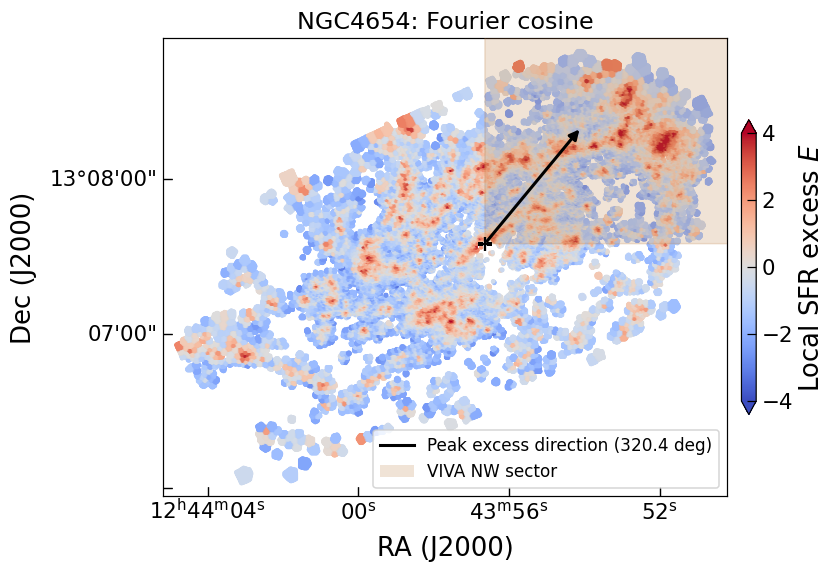

In [6]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# The plotted offsets are TAN plane coordinates in arcseconds.
ngc4654_centre = geometry_by_galaxy.loc['NGC4654']
ngc4654_sky_wcs = WCS(naxis=2)
ngc4654_sky_wcs.wcs.ctype = ['RA---TAN', 'DEC--TAN']
ngc4654_sky_wcs.wcs.crpix = [1, 1]  # Plot origin (0, 0) in zero-based coordinates.
ngc4654_sky_wcs.wcs.crval = [ngc4654_centre.center_ra_deg, ngc4654_centre.center_dec_deg]
ngc4654_sky_wcs.wcs.cdelt = [1 / 3600, 1 / 3600]
ngc4654_sky_wcs.wcs.radesys = 'FK5'
ngc4654_sky_wcs.wcs.equinox = 2000.0


def plot_ngc4654_arrow(pa_deg, title):
    fig_ngc4654_viva, ax_ngc4654 = plt.subplots(figsize=(7.5, 5.25), layout='constrained',
        subplot_kw=dict(projection=ngc4654_sky_wcs))
    east = ngc4654_map.east.to_numpy()
    north = ngc4654_map.north.to_numpy()
    excess_mesh = ax_ngc4654.scatter(east, north, c=ngc4654_map.excess,
        s=2, cmap='coolwarm', vmin=-4, vmax=4, rasterized=True, zorder=2)

    # The VIVA overlay is the reference notebook's coarse NW compass sector.
    viva_pa_min, viva_pa_max = 270, 360
    viva_angles = np.deg2rad(np.linspace(viva_pa_min, viva_pa_max, 100))
    viva_radius = 1.2 * np.hypot(east, north).max()
    viva_color = '#b87333'
    ax_ngc4654.fill(np.r_[0, viva_radius * np.sin(viva_angles), 0],
        np.r_[0, viva_radius * np.cos(viva_angles), 0],
        color=viva_color, alpha=0.20, zorder=3)

    muse_pa = np.deg2rad(pa_deg)
    arrow_length = 0.35 * min(np.ptp(east), np.ptp(north))
    ax_ngc4654.annotate('', xy=(arrow_length * np.sin(muse_pa), arrow_length * np.cos(muse_pa)),
        xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color='black', lw=2), zorder=5)
    ax_ngc4654.plot(0, 0, 'k+', ms=9, mew=1.5, zorder=4)
    ax_ngc4654.set(aspect='equal', xlim=(east.max() + 5, east.min() - 5),
        ylim=(north.min() - 5, north.max() + 5))
    ra_coord, dec_coord = ax_ngc4654.coords
    for coord, side, label, formatter in (
        (ra_coord, 'b', 'RA (J2000)', 'hh:mm:ss'),
        (dec_coord, 'l', 'Dec (J2000)', 'dd:mm:ss'),
    ):
        coord.set_ticks(number=4)
        coord.set_ticks_position(side)
        coord.set_ticklabel_position(side)
        coord.set_axislabel_position(side)
        coord.set_axislabel(label)
        coord.set_major_formatter(formatter)
        coord.set_ticklabel(exclude_overlapping=True)
    ax_ngc4654.legend(handles=[
        Line2D([], [], color='black', lw=2, label=f'Peak excess direction ({pa_deg:.1f} deg)'),
        Patch(facecolor=viva_color, alpha=0.20, label='VIVA NW sector')],
        loc='lower right', fontsize=11)
    ax_ngc4654.set_title(title)
    fig_ngc4654_viva.colorbar(excess_mesh, ax=ax_ngc4654, shrink=0.62, fraction=0.04, pad=0.025,
        extend='both', ticks=[-4, -2, 0, 2, 4],
        label=r'Local SFR excess $E$')
    plt.show()
    plt.close(fig_ngc4654_viva)


plot_ngc4654_arrow(ngc4654_fourier['PA_deg'], 'NGC4654: Fourier cosine')


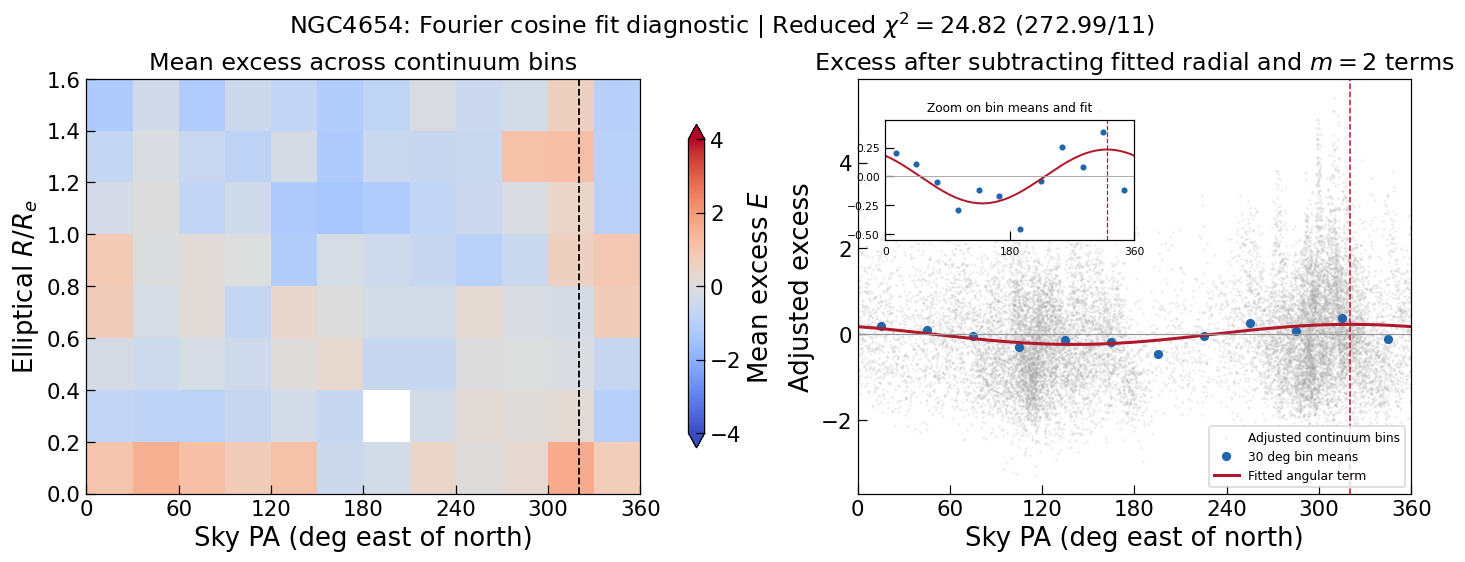

In [7]:
# Angular fit diagnostic adapted from cell 35 of the 20261015 NGC4654 notebook.
NGC4654_PA_EDGES = np.linspace(0, 360, 13)
# Two heatmap rows per fit annulus, retaining 0.2 Re visual bins.
NGC4654_RADIUS_EDGES = np.linspace(
    NGC4654_FIT_EDGES[0], NGC4654_FIT_EDGES[-1], 2 * (len(NGC4654_FIT_EDGES) - 1) + 1)


def ngc4654_excess_heatmap(frame):
    pa = np.rad2deg(frame.theta.to_numpy())
    radius = frame.r.to_numpy()
    grid = (NGC4654_PA_EDGES, NGC4654_RADIUS_EDGES)
    counts, _, _ = np.histogram2d(pa, radius, bins=grid)
    totals, _, _ = np.histogram2d(pa, radius, bins=grid, weights=frame.excess.to_numpy())
    assert counts.sum() == len(frame)
    means = np.divide(totals, counts, out=np.full_like(totals, np.nan), where=counts > 0)
    return means, counts


def ngc4654_annular_design(theta, radius, annuli):
    """Annular terms in the order of the fitted coefficients."""
    edges = NGC4654_FIT_EDGES
    annulus = np.minimum(np.searchsorted(edges, radius, side='right') - 1, len(edges) - 2)
    cos2, sin2 = np.cos(2 * theta), np.sin(2 * theta)
    columns = []
    for a in annuli:
        member = annulus == a
        centre = (edges[a] + edges[a + 1]) / 2
        columns.extend([member, member * (radius - centre), member * cos2, member * sin2])
    return np.column_stack(columns)


def ngc4654_fit_jacobian(theta, radius, peak_pa, amplitude, kappa, annuli):
    """Local derivatives of the bin-fit prediction."""
    nuisance = ngc4654_annular_design(theta, radius, annuli)
    if kappa == 0:
        angular = [np.cos(theta), np.sin(theta)]
    else:
        offset = theta - peak_pa
        cosine = np.cos(offset)
        top = np.tanh(kappa * cosine)
        denominator = np.tanh(kappa)
        shape = top / denominator
        # Derivatives with respect to amplitude, phase (radians) and log(kappa).
        phase_slope = amplitude * kappa * (1 - top**2) * np.sin(offset) / denominator
        log_kappa_slope = amplitude * kappa * (
            cosine * (1 - top**2) - shape * (1 - denominator**2)) / denominator
        angular = [shape, phase_slope, log_kappa_slope]
    return np.column_stack([nuisance, *angular])


def ngc4654_angular_reduced_chi2(frame, pa_deg, amplitude, kappa, *, localized_shape=None, localized_width_slope=None):
    # The bin-average adjusted excess minus the bin-average fitted angular term
    # is exactly the bin-average residual of the full model.
    theta = frame.theta.to_numpy()
    residual = (frame.excess - frame.fitted).to_numpy()
    edges = NGC4654_PA_EDGES
    sector = np.minimum(np.searchsorted(edges, np.rad2deg(theta), side='right') - 1,
                        len(edges) - 2)
    n_sectors = len(edges) - 1
    sector_count = np.bincount(sector, minlength=n_sectors)
    populated = sector_count > 0

    def sector_mean(values):
        return np.bincount(sector, weights=values, minlength=n_sectors)[populated] / sector_count[populated]

    # One residual per continuum bin. Project each bin's contribution through
    # the fit so the covariance accounts for estimating the model coefficients.
    assert frame.binid.is_unique
    fit_edges = NGC4654_FIT_EDGES
    radius = frame.r.to_numpy()
    annuli = np.unique(np.minimum(
        np.searchsorted(fit_edges, radius, side='right') - 1, len(fit_edges) - 2))
    if localized_shape is None:
        jacobian = ngc4654_fit_jacobian(theta, radius, np.deg2rad(pa_deg),
                                       amplitude, kappa, annuli)
    else:
        offset = theta - np.deg2rad(pa_deg)
        step = 1e-5  # radians; fixed width/kappa, differentiate only the fitted PA
        phase_slope = amplitude * (localized_shape(offset - step)
                                   - localized_shape(offset + step)) / (2 * step)
        columns = [ngc4654_annular_design(theta, radius, annuli),
                   localized_shape(offset), phase_slope]
        if localized_width_slope is not None:
            columns.append(amplitude * localized_width_slope(offset))
        jacobian = np.column_stack(columns)
    q, r = np.linalg.qr(jacobian, mode='reduced')
    if np.linalg.matrix_rank(r) != r.shape[1]:
        raise ValueError('Rank-deficient fit Jacobian for angular chi-square')
    direct = (np.flatnonzero(populated)[:, None] == sector) * residual
    direct /= sector_count[populated, None]
    mean_q = np.column_stack([sector_mean(column) for column in q.T])
    influences = direct - np.einsum('ij,jg->ig', mean_q, q.T * residual)
    bin_residuals = sector_mean(residual)
    if kappa == 0 and localized_shape is None:
        np.testing.assert_allclose(influences.sum(axis=1), bin_residuals, atol=1e-10)

    covariance = np.einsum('ig,jg->ij', influences, influences)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    keep = eigenvalues > eigenvalues.max() * 1e-10
    covariance_rank = int(keep.sum())
    if covariance_rank == 0:
        raise ValueError('Angular residual covariance has zero rank')
    standardized = np.einsum('ij,i->j', eigenvectors[:, keep], bin_residuals) / np.sqrt(eigenvalues[keep])
    chi2 = np.sum(standardized**2)
    return dict(chi2=chi2, covariance_rank=covariance_rank, reduced_chi2=chi2 / covariance_rank)


def plot_ngc4654_angular_diagnostic(frame, pa_deg, amplitude, kappa, title, *, localized_shape=None, localized_width_slope=None):
    assert frame.binid.is_unique
    pa_edges, radius_edges = NGC4654_PA_EDGES, NGC4654_RADIUS_EDGES
    pa = np.rad2deg(frame.theta.to_numpy())
    observed = frame.excess.to_numpy()
    angular = frame.angular.to_numpy()
    fitted = frame.fitted.to_numpy()
    adjusted = observed - (fitted - angular)
    np.testing.assert_allclose(adjusted - angular, observed - fitted, atol=1e-12)

    mean_2d, _ = ngc4654_excess_heatmap(frame)
    count_1d = np.histogram(pa, bins=pa_edges)[0]
    total_1d = np.histogram(pa, bins=pa_edges, weights=adjusted)[0]
    means = np.divide(total_1d, count_1d, out=np.full_like(total_1d, np.nan),
                      where=count_1d > 0)
    centres = (pa_edges[:-1] + pa_edges[1:]) / 2

    grid = np.linspace(0, 360, 721)
    cosine = np.cos(np.deg2rad(grid - pa_deg))
    if localized_shape is None:
        curve = amplitude * (np.tanh(kappa * cosine) / np.tanh(kappa) if kappa > 0 else cosine)
    else:
        curve = amplitude * localized_shape(np.deg2rad(grid - pa_deg))
    fig, (ax_radial, ax_angular) = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
    mesh = ax_radial.pcolormesh(pa_edges, radius_edges, mean_2d.T, cmap='coolwarm',
                               vmin=-4, vmax=4, shading='flat')
    ax_radial.axvline(pa_deg, color='black', ls='--', lw=1.2)
    ax_radial.set(xlim=(0, 360), ylim=(radius_edges[0], radius_edges[-1]), xticks=np.arange(0, 361, 60),
                  xlabel='Sky PA (deg east of north)', ylabel=r'Elliptical $R/R_e$',
                  title='Mean excess across continuum bins')
    fig.colorbar(mesh, ax=ax_radial, shrink=0.78, extend='both', label=r'Mean excess $E$')

    ax_angular.scatter(pa, adjusted, s=1, color='0.65', alpha=0.12, rasterized=True,
                       label='Adjusted continuum bins')
    ax_angular.plot(centres, means, 'o', ms=5, color='#2166ac',
                    label='30 deg bin means')
    if localized_shape is not None:
        # Average the model over the actual sampled PAs in each bin.
        total_model = np.histogram(pa, bins=pa_edges, weights=angular)[0]
        model_means = np.divide(total_model, count_1d, out=np.full_like(total_model, np.nan),
                                where=count_1d > 0)
        ax_angular.plot(centres, model_means, 'x', ms=5, color='#b2182b',
                        label='Fit averaged in 30 deg bins')
    ax_angular.plot(grid, curve, color='#b2182b', lw=2, label='Fitted angular term')
    ax_angular.axhline(0, color='0.6', lw=0.8)
    ax_angular.axvline(pa_deg, color='#b2182b', ls='--', lw=1)
    ax_angular.set(xlim=(0, 360), xticks=np.arange(0, 361, 60),
                   xlabel='Sky PA (deg east of north)', ylabel='Adjusted excess',
                   title=r'Excess after subtracting fitted radial and $m=2$ terms')
    ax_angular.legend(fontsize=8, loc='lower right')

    inset = ax_angular.inset_axes([0.05, 0.61, 0.45, 0.29])
    inset.plot(centres, means, 'o', ms=3, color='#2166ac')
    if localized_shape is not None:
        inset.plot(centres, model_means, 'x', ms=3, color='#b2182b')
    inset.plot(grid, curve, color='#b2182b', lw=1.3)
    inset.axhline(0, color='0.65', lw=0.6)
    inset.axvline(pa_deg, color='#b2182b', ls='--', lw=0.8)
    lo, hi = np.nanmin(np.r_[means, curve]), np.nanmax(np.r_[means, curve])
    pad = 0.12 * max(hi - lo, 1e-6)
    inset.set(xlim=(0, 360), ylim=(lo - pad, hi + pad), xticks=[0, 180, 360],
              title='Zoom on bin means and fit')
    inset.title.set_fontsize(8)
    inset.tick_params(labelsize=7)
    chi2_summary = ngc4654_angular_reduced_chi2(
        frame, pa_deg, amplitude, kappa, localized_shape=localized_shape,
        localized_width_slope=localized_width_slope)
    chi2 = chi2_summary['chi2']
    dof = chi2_summary['covariance_rank']
    reduced = chi2_summary['reduced_chi2']
    fig.suptitle(title + fr' | Reduced $\chi^2={reduced:.2f}$ ({chi2:.2f}/{dof})')
    plt.show()
    plt.close(fig)
    return chi2_summary


ngc4654_cosine_chi2 = plot_ngc4654_angular_diagnostic(
    ngc4654_cosine_diagnostics, ngc4654_fourier['PA_deg'],
    ngc4654_fourier['amplitude_W'],
    0.0, 'NGC4654: Fourier cosine fit diagnostic')


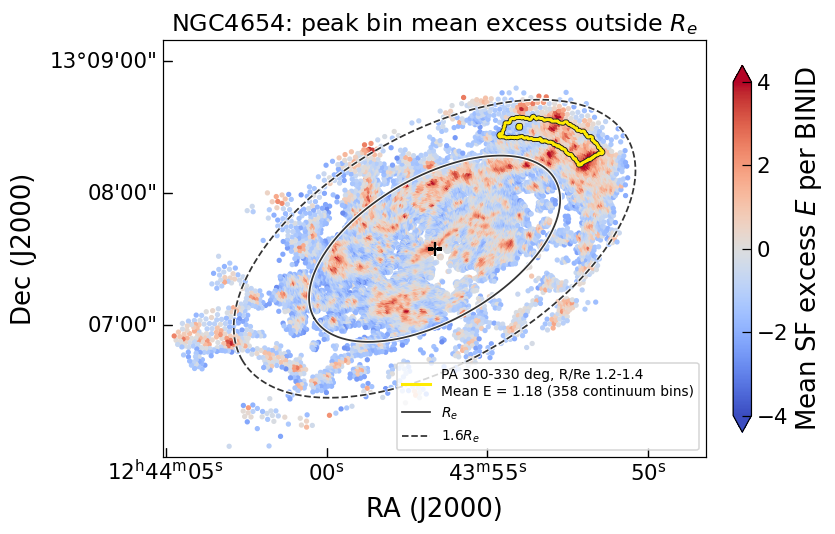

In [8]:
# Locate the highest mean of continuum-bin excesses outside Re.
from matplotlib import patheffects

fit_bins = ngc4654_cosine_diagnostics
heatmap_means, heatmap_counts = ngc4654_excess_heatmap(fit_bins)
outer_rows = NGC4654_RADIUS_EDGES[:-1] >= 1.0
outer_heatmap_means = np.where(outer_rows[None, :], heatmap_means, np.nan)
if not np.isfinite(outer_heatmap_means).any():
    raise ValueError('No populated continuum-bin sectors outside Re.')
peak_pa_bin, peak_r_bin = np.unravel_index(
    np.nanargmax(outer_heatmap_means), outer_heatmap_means.shape)
peak_pa_bounds = NGC4654_PA_EDGES[peak_pa_bin:peak_pa_bin + 2]
peak_r_bounds = NGC4654_RADIUS_EDGES[peak_r_bin:peak_r_bin + 2]
peak_mean_excess = heatmap_means[peak_pa_bin, peak_r_bin]

# Match histogram2d: lower edges inclusive, upper edges exclusive except at the end.
fit_pa = np.rad2deg(fit_bins.theta.to_numpy())
fit_r = fit_bins.r.to_numpy()
pa_index = np.minimum(np.searchsorted(NGC4654_PA_EDGES, fit_pa, side='right') - 1,
                      len(NGC4654_PA_EDGES) - 2)
r_index = np.minimum(np.searchsorted(NGC4654_RADIUS_EDGES, fit_r, side='right') - 1,
                     len(NGC4654_RADIUS_EDGES) - 2)
peak_bins = fit_bins.loc[(pa_index == peak_pa_bin) & (r_index == peak_r_bin)]
assert len(peak_bins) == heatmap_counts[peak_pa_bin, peak_r_bin]
np.testing.assert_allclose(peak_bins.excess.mean(), peak_mean_excess)

# Outline every native pixel of each selected continuum BINID.
mass_path = inventory.loc[inventory.galaxy.eq('NGC4654'), 'mass'].item()
mass_header = fits.getheader(mass_path, 'LOGMASS_SURFACE_DENSITY')
native_wcs = WCS(mass_header).celestial
peak_y, peak_x = np.nonzero(np.isin(ngc4654_native_binid, peak_bins.binid.to_numpy()))
# Include a one-pixel border so the contour closes at the edge of the data.
contour_x = np.arange(peak_x.min() - 1, peak_x.max() + 2)
contour_y = np.arange(peak_y.min() - 1, peak_y.max() + 2)
peak_mask = np.zeros((len(contour_y), len(contour_x)), dtype=bool)
peak_mask[peak_y - contour_y[0], peak_x - contour_x[0]] = True

fig_corner, ax_corner = plt.subplots(
    figsize=(7.5, 5.25), layout='constrained', subplot_kw={'projection': ngc4654_sky_wcs})
map_east = ngc4654_bins.east.to_numpy()
map_north = ngc4654_bins.north.to_numpy()
peak_mesh = ax_corner.scatter(
    map_east, map_north, c=ngc4654_bins.excess, cmap='coolwarm',
    vmin=-4, vmax=4, s=6, rasterized=True)
peak_outline = ax_corner.contour(
    contour_x, contour_y, peak_mask.astype(float), levels=[0.5],
    transform=ax_corner.get_transform(native_wcs),
    colors=['#ffeb00'], linewidths=1.8, zorder=5)
peak_outline.set_path_effects([patheffects.Stroke(linewidth=3.0, foreground='0.15'),
                                patheffects.Normal()])
ax_corner.plot(0, 0, 'k+', ms=9, mew=1.5)
# Invert the same major/minor-axis rotation used for the heatmap radius.
ellipse_angle = np.linspace(0, 2 * np.pi, 361)
major_pa = np.deg2rad(ngc4654_centre.pa_deg_east_of_north)
major = ngc4654_centre.a_re_arcsec * np.cos(ellipse_angle)
minor = ngc4654_centre.b_re_arcsec * np.sin(ellipse_angle)
re_east = major * np.sin(major_pa) + minor * np.cos(major_pa)
re_north = major * np.cos(major_pa) - minor * np.sin(major_pa)
radius_lines = []
fit_outer_radius = NGC4654_FIT_EDGES[-1]
for scale, linestyle, radius_label in [(1, '-', r'$R_e$'),
                                       (fit_outer_radius, '--', fr'{fit_outer_radius:g}$R_e$')]:
    line, = ax_corner.plot(scale * re_east, scale * re_north, color='0.2',
                           ls=linestyle, lw=1.15, label=radius_label, zorder=4)
    line.set_path_effects([patheffects.Stroke(linewidth=2.5, foreground='white'),
                           patheffects.Normal()])
    radius_lines.append(line)
east_limit = max(np.abs(map_east).max(), fit_outer_radius * np.abs(re_east).max()) + 5
north_limit = max(np.abs(map_north).max(), fit_outer_radius * np.abs(re_north).max()) + 5
ax_corner.set(title=r'NGC4654: peak bin mean excess outside $R_e$', aspect='equal',
              xlim=(east_limit, -east_limit), ylim=(-north_limit, north_limit))
for coord, side, label, formatter in (
    (ax_corner.coords[0], 'b', 'RA (J2000)', 'hh:mm:ss'),
    (ax_corner.coords[1], 'l', 'Dec (J2000)', 'dd:mm:ss'),
):
    coord.set_ticks(number=4)
    coord.set_ticks_position(side)
    coord.set_ticklabel_position(side)
    coord.set_major_formatter(formatter)
    coord.set_ticklabel(exclude_overlapping=True)
    coord.set_axislabel(label)
pa_lo, pa_hi = peak_pa_bounds
r_lo, r_hi = peak_r_bounds
label = (f'PA {pa_lo:.0f}-{pa_hi:.0f} deg, R/Re {r_lo:.1f}-{r_hi:.1f}'
         f'\nMean E = {peak_mean_excess:.2f} ({len(peak_bins)} continuum bins)')
ax_corner.legend(handles=[Line2D([], [], color='#ffeb00', lw=2, label=label),
                          *radius_lines],
                 loc='lower right', fontsize=9)
fig_corner.colorbar(peak_mesh, ax=ax_corner, shrink=0.73, extend='both', label=r'Mean SF excess $E$ per BINID')
plt.show()
plt.close(fig_corner)


## Fourier cosine fit with four annular amplitudes

$$
\begin{aligned}
\widehat E_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A_a\cos(\phi_i-\theta)}_{m=1}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

Use the same four annuli, continuum bins, and annular intercepts, radial slopes and \(m=2\) terms as the original Fourier fit. Replace its shared amplitude with \(A_a\cos(\phi-\theta)\), where each annulus has its own \(A_a\geq0\) and all four share one sky PA \(\theta\). The nonnegative constraint gives the amplitudes a common enhancement direction and lets an annulus have zero modulation. At each trial PA, solve for the annular amplitudes and nuisance terms, then minimize the total residual sum of squares over PA.

The shared-amplitude fit is a special case of this model. Compare RSS, RMSE, and \(R^2\) on the identical bins to see how much the three extra amplitude parameters improve the in-sample fit. The annular panel shows means in 30° PA bins after subtracting the nuisance terms of the new fit.

In [9]:
def fit_ngc4654_annular_amplitudes(frame):
    """Fit a shared Fourier phase and one nonnegative amplitude per annulus."""
    from scipy.optimize import minimize_scalar

    assert frame.binid.is_unique
    theta, radius, y = (frame[col].to_numpy(float) for col in ('theta', 'r', 'excess'))
    edges = NGC4654_FIT_EDGES
    annuli = np.arange(len(edges) - 1)
    annulus = np.minimum(np.searchsorted(edges, radius, side='right') - 1, annuli[-1])
    if not np.array_equal(np.unique(annulus), annuli):
        raise ValueError('All four Fourier annuli must be populated')
    design = ngc4654_annular_design(theta, radius, annuli)
    q, r = np.linalg.qr(design, mode='reduced')
    if np.linalg.cond(r) > 1e6:
        raise ValueError('Poorly conditioned annular design')

    def residualize(values):
        return values - np.einsum('ij,j...->i...', q, np.einsum('ij,i...->j...', q, values))

    y0 = residualize(y)
    basis = np.column_stack([np.cos(theta), np.sin(theta)])
    basis0 = residualize(basis)
    # The nuisance design is block diagonal by annulus. Its residualized
    # cosine and sine columns give the linear fit for any shared phase.
    gram = np.stack([np.einsum('ni,nj->ij', basis0[annulus == a], basis0[annulus == a])
                     for a in annuli])
    score = np.stack([np.einsum('ni,n->i', basis0[annulus == a], y0[annulus == a])
                      for a in annuli])
    if np.any(np.linalg.eigvalsh(gram)[:, 0] <= 0):
        raise ValueError('An annulus cannot identify the Fourier amplitude')

    def profile(pa):
        direction = np.array([np.cos(pa), np.sin(pa)])
        numerator = np.maximum(0.0, np.einsum('ai,i->a', score, direction))
        denominator = np.einsum('i,aij,j->a', direction, gram, direction)
        amplitude = numerator / denominator
        return np.sum(numerator * amplitude), amplitude

    # Evaluate the full circle and refine each candidate peak continuously,
    # including peaks at the 0/360 seam.
    grid = np.deg2rad(np.arange(360.0))
    gains = np.array([profile(pa)[0] for pa in grid])
    peaks = np.flatnonzero((gains > 0) & (gains >= np.roll(gains, 1))
                          & (gains >= np.roll(gains, -1)))
    if peaks.size == 0:
        raise ValueError('No identifiable shared Fourier phase')
    step = grid[1]
    fits = [minimize_scalar(lambda pa: -profile(pa)[0], method='bounded',
                            bounds=(grid[i] - step, grid[i] + step),
                            options={'xatol': 1e-12}) for i in peaks]
    if not all(fit.success for fit in fits):
        raise RuntimeError('Annular Fourier phase refinement failed')
    pa = min(fits, key=lambda fit: fit.fun).x % (2 * np.pi)
    gain, amplitude = profile(pa)
    angular = amplitude[annulus] * np.cos(theta - pa)
    nuisance_coeff = np.linalg.solve(r, np.einsum('ij,i->j', q, y - angular))
    prediction = np.einsum('ij,j->i', design, nuisance_coeff) + angular
    np.testing.assert_allclose(np.sum(y0**2) - np.sum((y - prediction)**2), gain,
                               rtol=1e-9, atol=1e-10)
    return np.rad2deg(pa) % 360, amplitude, frame.assign(
        annulus=annulus, fitted=prediction, angular=angular)

,PA_deg,N_BINID,RSS,RMSE_W,R2,RSS_reduction_pct
model,,,,,,
Shared amplitude,320.396471,16885,22115.883137,1.144463,0.129485,0.0000
Four annular amplitudes,336.306846,16885,21616.860255,1.131477,0.149127,2.2564


,N_BINID,shared_amplitude_W,free_amplitude_W,shared_RMSE_W,free_RMSE_W
annulus,,,,,
0.0-0.4 Re,4440,0.233871,0.225692,0.933906,0.935753
0.4-0.8 Re,6436,0.233871,0.013555,1.104703,1.091930
0.8-1.2 Re,3909,0.233871,0.544245,1.282418,1.260078
1.2-1.6 Re,2100,0.233871,0.654805,1.373279,1.353766


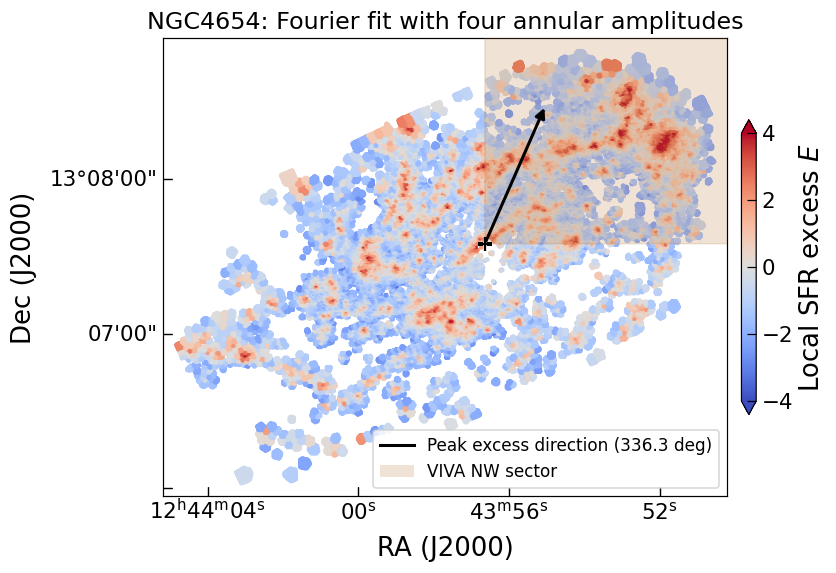

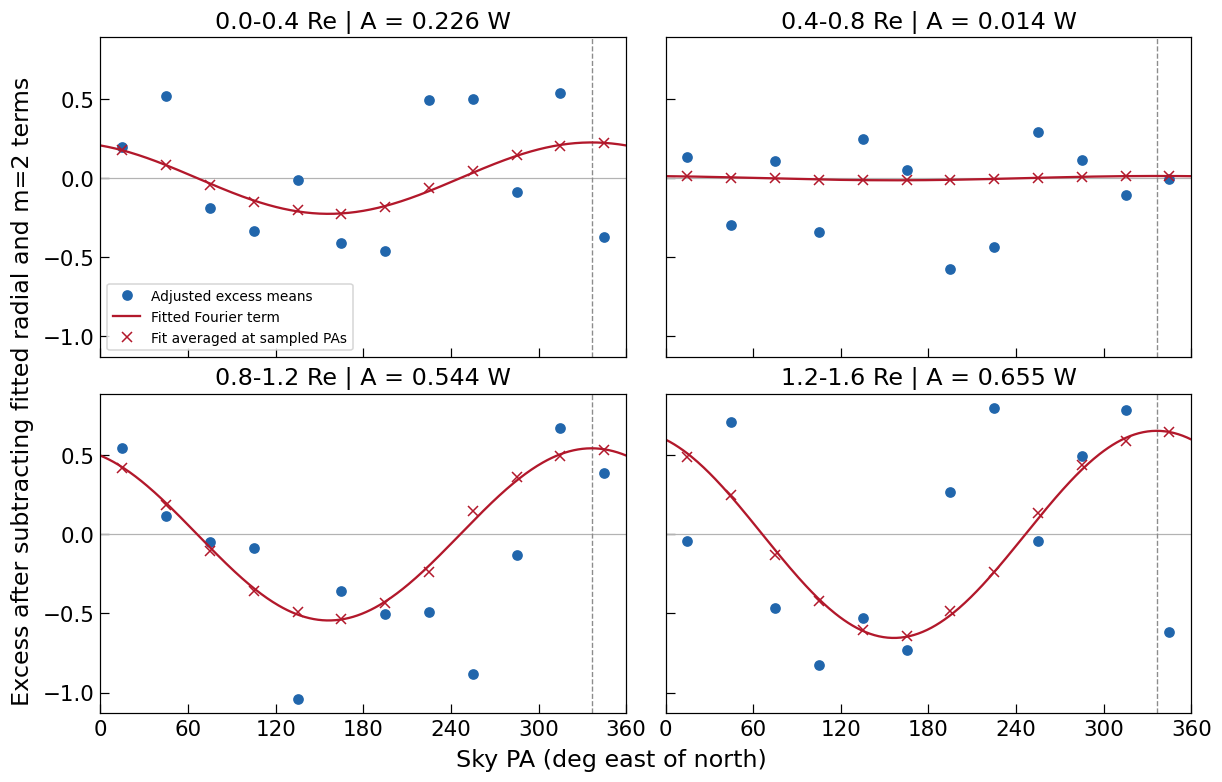

In [10]:
ngc4654_annular_pa, ngc4654_annular_amplitudes, ngc4654_annular_diagnostics = (
    fit_ngc4654_annular_amplitudes(ngc4654_cosine_diagnostics))
original = ngc4654_cosine_diagnostics
annular_fit = ngc4654_annular_diagnostics
assert annular_fit[['theta', 'r', 'binid', 'excess']].equals(original[['theta', 'r', 'binid', 'excess']])
observed = original.excess.to_numpy()
comparison_rows = []
for model, pa, fitted in (
    ('Shared amplitude', ngc4654_fourier['PA_deg'], original.fitted),
    ('Four annular amplitudes', ngc4654_annular_pa, annular_fit.fitted),
):
    rss = np.sum((observed - fitted.to_numpy())**2)
    comparison_rows.append(dict(model=model, PA_deg=pa, N_BINID=len(observed), RSS=rss,
                                RMSE_W=np.sqrt(rss / len(observed)),
                                R2=1 - rss / np.sum((observed - observed.mean())**2)))
ngc4654_annular_comparison = pd.DataFrame(comparison_rows).set_index('model')
shared_rss = ngc4654_annular_comparison.loc['Shared amplitude', 'RSS']
assert ngc4654_annular_comparison.loc['Four annular amplitudes', 'RSS'] <= shared_rss + 1e-8
ngc4654_annular_comparison['RSS_reduction_pct'] = 100 * (
    1 - ngc4654_annular_comparison.RSS / shared_rss)
display(ngc4654_annular_comparison.round(6))

annular_rows = []
for a, amplitude in enumerate(ngc4654_annular_amplitudes):
    take = annular_fit.annulus.eq(a)
    residuals_shared = original.excess[take] - original.fitted[take]
    residuals_free = annular_fit.excess[take] - annular_fit.fitted[take]
    annular_rows.append(dict(
        annulus=f'{NGC4654_FIT_EDGES[a]:.1f}-{NGC4654_FIT_EDGES[a+1]:.1f} Re',
        N_BINID=int(take.sum()), shared_amplitude_W=ngc4654_fourier['amplitude_W'],
        free_amplitude_W=amplitude,
        shared_RMSE_W=np.sqrt(np.mean(residuals_shared**2)),
        free_RMSE_W=np.sqrt(np.mean(residuals_free**2))))
ngc4654_annular_summary = pd.DataFrame(annular_rows).set_index('annulus')
display(ngc4654_annular_summary.round(6))

plot_ngc4654_arrow(ngc4654_annular_pa, 'NGC4654: Fourier fit with four annular amplitudes')
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True, layout='constrained')
pa_edges = NGC4654_PA_EDGES
pa_centres = (pa_edges[1:] + pa_edges[:-1]) / 2
pa_grid = np.linspace(0, 360, 361)
for a, ax in enumerate(axes.flat):
    ann = annular_fit.loc[annular_fit.annulus.eq(a)]
    pa = np.rad2deg(ann.theta.to_numpy())
    adjusted = (ann.excess - (ann.fitted - ann.angular)).to_numpy()
    counts = np.histogram(pa, bins=pa_edges)[0]

    def bin_means(values):
        totals = np.histogram(pa, bins=pa_edges, weights=values)[0]
        return np.divide(totals, counts, out=np.full_like(totals, np.nan), where=counts > 0)

    amplitude = ngc4654_annular_amplitudes[a]
    ax.axhline(0, color='0.7', lw=0.8)
    ax.axvline(ngc4654_annular_pa, color='0.55', ls='--', lw=0.9)
    ax.plot(pa_centres, bin_means(adjusted), 'o', color='#2166ac', label='Adjusted excess means')
    ax.plot(pa_grid, amplitude * np.cos(np.deg2rad(pa_grid - ngc4654_annular_pa)),
            color='#b2182b', label='Fitted Fourier term')
    ax.plot(pa_centres, bin_means(ann.angular.to_numpy()), 'x', color='#b2182b',
            label='Fit averaged at sampled PAs')
    ax.set(xlim=(0, 360), xticks=np.arange(0, 361, 60),
           title=f'{ngc4654_annular_summary.index[a]} | A = {amplitude:.3f} W')
axes[0, 0].legend(fontsize=9, loc='best')
fig.supxlabel('Sky PA (deg east of north)')
fig.supylabel('Excess after subtracting fitted radial and m=2 terms')
plt.show()
plt.close(fig)

## Smooth opposite-half fit

$$
\begin{aligned}
\widehat E_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A\,\frac{\tanh[\kappa\cos(\phi_i-\theta)]}{\tanh\kappa}}_{\text{opposite-half term}}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

Fit the shared angular term with \(A\tanh[\kappa\cos(\phi-\theta)]/\tanh\kappa\), following the shape proposed in [Fourier Approach Assessment](https://chatgpt.com/c/6afba860-2ac0-83ec-8ae5-877d28f9c267). The transition sharpness \(\kappa\) and sky PA \(\theta\), east of north, are fitted jointly. The amplitude \(A\geq0\) is the peak angular excess, so the contrast between opposite central directions is \(2A\). For \(\kappa>0\), this parameterization has \(\gamma=A/\tanh\kappa\) in the original formula. Its \(\kappa=0\) limit is the Fourier cosine.

Use the same continuum bins with centroids within \(1.6R_e\) and four annular nuisance terms per populated annulus (intercept, radial slope, and the \(m=2\) cosine/sine pair). Give each continuum bin equal weight and refit the nuisance coefficients for each model. Compare in-sample \(R^2\) and RMSE on the same footprint. The table reports point estimates for this alternative, and the diagnostic below compares the fitted angular curve with excess after subtracting the fitted annular terms.

The angular diagnostics report generalized reduced \(\chi^2\), using the rank of the covariance of the 30 deg bin residual means as the denominator. Each fitted BINID contributes one residual, and the covariance accounts for estimating the model from those same bin means. The positive-\(\kappa\) covariance uses local fit derivatives. At \(\kappa=0\), the diagnostic uses the cosine limit. The statistic describes fit adequacy on this footprint.

In [11]:
from scipy.optimize import minimize


def compare_ngc4654_angular_models(frame):
    edges = NGC4654_FIT_EDGES
    theta = np.arctan2(frame.east.to_numpy(), frame.north.to_numpy()) % (2 * np.pi)
    radius = frame.r.to_numpy()
    binid = frame.binid.to_numpy()
    excess = frame.excess.to_numpy()
    keep = (np.isfinite(binid) & (binid >= 0) & (binid == np.floor(binid))
            & (np.hypot(frame.east.to_numpy(), frame.north.to_numpy()) > 0)
            & np.isfinite(theta) & (radius >= edges[0]) & (radius <= edges[-1])
            & np.isfinite(excess))
    theta, radius, y = theta[keep], radius[keep], excess[keep]
    bins = np.unique(binid[keep].astype(np.int64))
    annulus = np.minimum(np.searchsorted(edges, radius, side='right') - 1, len(edges) - 2)
    columns = []
    for a in np.unique(annulus):
        member = annulus == a
        center = (edges[a] + edges[a + 1]) / 2
        columns.extend([member, member * (radius - center),
                        member * np.cos(2 * theta), member * np.sin(2 * theta)])
    nuisance = np.column_stack(columns)
    q, r = np.linalg.qr(nuisance, mode='reduced')
    if np.linalg.cond(r) > 1e6:
        raise ValueError('Poorly conditioned annular design')
    nuisance_score = np.einsum('ij,i->j', q, y)
    residual_y = y - np.einsum('ij,j->i', q, nuisance_score)
    cos_theta, sin_theta = np.cos(theta), np.sin(theta)

    def half_column(pa, kappa):
        cosine = cos_theta * np.cos(pa) + sin_theta * np.sin(pa)
        # Unit peak keeps amplitude well defined through the cosine limit.
        return np.tanh(kappa * cosine) / np.tanh(kappa) if kappa > 0 else cosine

    def profile(pa, kappa):
        # Solve the linear amplitude and nuisance terms at each trial PA and kappa.
        column = half_column(pa, kappa)
        projection = np.einsum('ij,i->j', q, column)
        norm2 = np.dot(column, column) - np.dot(projection, projection)
        if norm2 <= 0:
            raise ValueError('Half template is degenerate with the annular terms')
        score = max(0.0, np.dot(column, residual_y))
        return score**2 / norm2, score / norm2, projection

    period = 2 * np.pi

    cosine_design = np.column_stack([nuisance, cos_theta, sin_theta])
    cosine_coeff, _, rank, _ = np.linalg.lstsq(
        cosine_design, y, rcond=None)
    if rank != cosine_design.shape[1]:
        raise ValueError('Rank-deficient cosine design')
    cosine_prediction = np.einsum('ij,j->i', cosine_design, cosine_coeff)
    c1, s1 = cosine_coeff[-2:]
    cosine_amp = np.hypot(c1, s1)
    cosine_pa = np.arctan2(s1, c1) % period
    # Seed the continuous search over PA and log(kappa) on a periodic PA grid.
    # The exact kappa=0 limit is supplied by the independent cosine fit.
    pa_grid = np.linspace(0.0, period, 72, endpoint=False)
    pa_step = pa_grid[1]
    log_kappa_grid = np.log([0.01, 0.05, 0.125, 0.25, 0.5, 1, 2, 4, 8,
                             16, 32, 64, 128, 512, 2048, 8192, 32768])
    gains = np.array([[profile(pa, np.exp(log_kappa))[0] for pa in pa_grid]
                      for log_kappa in log_kappa_grid])
    pa_peaks = (gains >= np.roll(gains, 1, axis=1)) & (gains >= np.roll(gains, -1, axis=1))
    kappa_peaks = ((gains >= np.vstack([gains[:1], gains[:-1]]))
                   & (gains >= np.vstack([gains[1:], gains[-1:]])))
    peaks = np.argwhere((gains > 0) & pa_peaks & kappa_peaks)
    solutions = []
    for k, p in peaks:
        pa = pa_grid[p]
        bounds = [(pa - pa_step, pa + pa_step),
                  (log_kappa_grid[max(0, k - 1)], log_kappa_grid[min(k + 1, len(log_kappa_grid) - 1)])]
        fit = minimize(lambda trial: -profile(trial[0], np.exp(trial[1]))[0],
                       x0=[pa, log_kappa_grid[k]], bounds=bounds, method='L-BFGS-B',
                       options={'ftol': 1e-12, 'gtol': 1e-5})
        if not fit.success:
            raise RuntimeError(f'Opposite-half fit did not converge: {fit.message}')
        solutions.append(fit)
    best = min(solutions, key=lambda fit: fit.fun)
    half_pa, log_kappa = best.x
    kappa = np.exp(log_kappa)
    cosine_gain = np.dot(residual_y, residual_y) - np.sum((y - cosine_prediction)**2)
    if -best.fun <= cosine_gain + 1e-8:
        half_pa, kappa = cosine_pa, 0.0
    elif np.isclose(log_kappa, log_kappa_grid[0]) or np.isclose(log_kappa, log_kappa_grid[-1]):
        raise RuntimeError('Opposite-half sharpness reached a numerical search limit')
    half_gain, half_peak, projection = profile(half_pa, kappa)
    half_baseline = np.linalg.solve(r, nuisance_score - half_peak * projection)
    half_angular = half_peak * half_column(half_pa, kappa)
    half_prediction = np.einsum('ij,j->i', nuisance, half_baseline) + half_angular
    np.testing.assert_allclose(
        np.dot(residual_y, residual_y) - np.sum((y - half_prediction)**2),
        half_gain, rtol=1e-10)

    tss = np.sum((y - y.mean())**2)

    rows = []
    for name, prediction, pa, amplitude, sharpness in (
        ('Fourier cosine', cosine_prediction, cosine_pa, cosine_amp, 0.0),
        ('Smooth opposite-half', half_prediction, half_pa, half_peak, kappa),
    ):
        rss = np.sum((y - prediction)**2)
        rows.append(dict(model=name, PA_deg=np.rad2deg(pa), amplitude_W=amplitude,
                         kappa=sharpness, central_direction_contrast_W=2 * amplitude, RSS=rss,
                         RMSE_W=np.sqrt(rss / len(y)), R2=1 - rss / tss))
    comparison = pd.DataFrame(rows).set_index('model')
    diagnostics = pd.DataFrame(dict(theta=theta, r=radius, binid=binid[keep].astype(np.int64), excess=y,
                                    fitted=half_prediction, angular=half_angular))
    return comparison, diagnostics, len(bins)


ngc4654_angular_comparison, ngc4654_half_diagnostics, ngc4654_angular_bin_count = (
    compare_ngc4654_angular_models(ngc4654_bins))
cosine_row, half_row = (ngc4654_angular_comparison.loc[name]
                        for name in ('Fourier cosine', 'Smooth opposite-half'))
np.testing.assert_allclose(
    [cosine_row.PA_deg, cosine_row.amplitude_W, cosine_row.R2],
    [ngc4654_fourier['PA_deg'], ngc4654_fourier['amplitude_W'],
     ngc4654_fourier['goodness'].loc['All fitted annuli', 'R2_full']],
    rtol=1e-8, atol=1e-8)
assert len(ngc4654_half_diagnostics) == len(ngc4654_cosine_diagnostics)
assert ngc4654_angular_bin_count == ngc4654_fourier['N_BINID']
for column in ('theta', 'r', 'binid', 'excess'):
    np.testing.assert_allclose(ngc4654_half_diagnostics[column], ngc4654_cosine_diagnostics[column])
pa_shift = (half_row.PA_deg - cosine_row.PA_deg + 180) % 360 - 180
rss_reduction_pct = 100 * (1 - half_row.RSS / cosine_row.RSS)
display(ngc4654_angular_comparison.round(6))
print(f'Fitted opposite-half kappa: {half_row.kappa:.6g}')
print(f'Opposite-half minus cosine PA: {pa_shift:+.2f} deg')
print(f'RSS reduction relative to cosine: {rss_reduction_pct:+.3f}%')


,PA_deg,amplitude_W,kappa,central_direction_contrast_W,RSS,RMSE_W,R2
model,,,,,,,
Fourier cosine,320.396471,0.233871,0.000000,0.467742,22115.883137,1.144463,0.129485
Smooth opposite-half,338.255022,0.200137,29.447423,0.400273,22086.824902,1.143711,0.130629


Fitted opposite-half kappa: 29.4474
Opposite-half minus cosine PA: +17.86 deg
RSS reduction relative to cosine: +0.131%


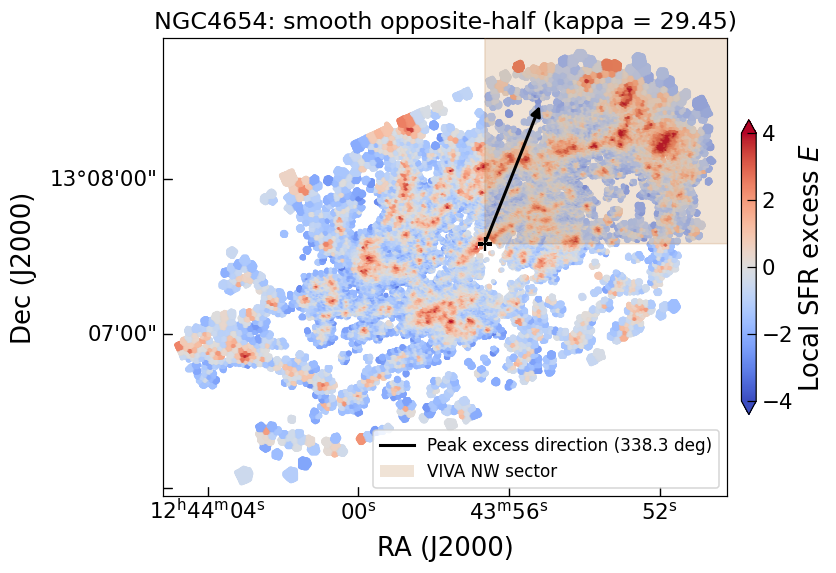

In [12]:
plot_ngc4654_arrow(half_row.PA_deg,
                   f'NGC4654: smooth opposite-half (kappa = {half_row.kappa:.2f})')


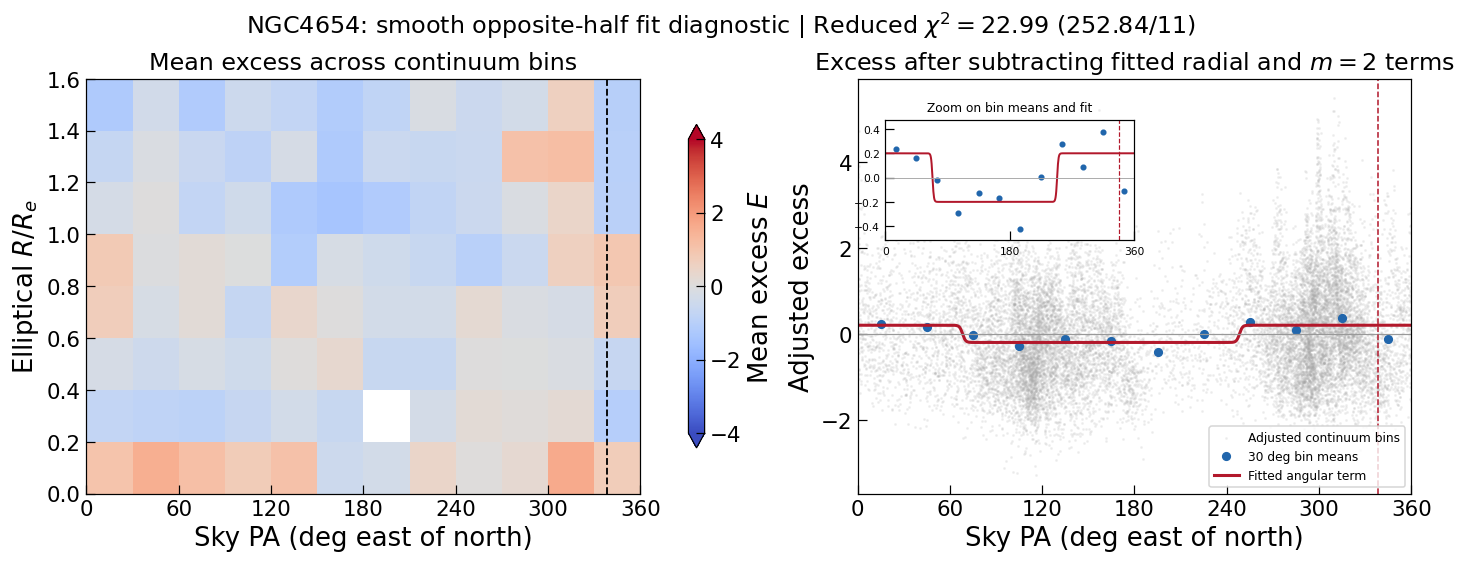

In [13]:
ngc4654_half_chi2 = plot_ngc4654_angular_diagnostic(
    ngc4654_half_diagnostics, half_row.PA_deg, half_row.amplitude_W,
    half_row.kappa, 'NGC4654: smooth opposite-half fit diagnostic')


## Smooth opposite-sector fit

$$
\begin{aligned}
\widehat E_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A\,\frac{h_{\rm sec}(u_i;w,\kappa)}{h_{\rm sec}(1;w,\kappa)}}_{\text{opposite-sector term}}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

$$
\begin{aligned}
u_i &= \cos(\phi_i-\theta),\\
h_{\rm sec}(u;w,\kappa)
&=\tfrac12\left[
\tanh\!\bigl(\kappa[u-\cos(w/2)]\bigr)
-\tanh\!\bigl(\kappa[-u-\cos(w/2)]\bigr)
\right].
\end{aligned}
$$

Here \(w=45^\circ\) for the primary fit and \(\kappa=40\).

Use the smooth sector template from [Fourier Approach Assessment](https://chatgpt.com/c/6afba860-2ac0-83ec-8ae5-877d28f9c267). With \(c=\cos(\phi-\theta)\), set \(h(c)=[\tanh(\kappa[c-\cos\alpha])-\tanh(\kappa[-c-\cos\alpha])]/2\) and use \(A h(c)/h(1)\) as the shared angular term. The primary settings are a **45° total width per sector** (\(\alpha=22.5^\circ\)) and \(\kappa=40\). The positive and negative sectors are separated by 180°; the fitted term is near zero away from both. Normalizing to unit peak makes \(A\) the peak excess in units of \(W\) and \(2A\) the central direction contrast, as in the earlier fits.

Fit the PA (east of north) over the full circle. At each PA, solve for the shared amplitude and refit the four nuisance coefficients per populated annulus (intercept, radial slope, and \(m=2\) sine and cosine). Both new models use the same equal-weight continuum bins within \(1.6R_e\) as the Fourier fit. The width check below reports all four prespecified sector widths at fixed sharpness. The 45° fit is the primary comparison regardless of which width gives the lowest RSS.

The angular diagnostic compares the adjusted excess with both the continuous template and its mean over the sampled angles in each 30° bin. Its reduced \(\chi^2\) uses the local fit derivatives for amplitude and PA at fixed shape. These are descriptive fits; the narrow templates contain higher odd harmonics and can be sensitive to individual SF complexes.

In [14]:
def ngc4654_localized_shape(offset, model, width_deg, kappa):
    """Unit-peak, antipodal angular template (offset in radians)."""
    c = np.clip(np.cos(offset), -1.0, 1.0)
    if model == 'sector':
        threshold = np.cos(np.deg2rad(width_deg / 2))
        def difference(x):
            return np.tanh(kappa * (x - threshold)) - np.tanh(kappa * (-x - threshold))
        return difference(c) / difference(1.0)
    if model == 'lobes':
        if kappa == 0:
            return c  # cosine limit, with a 120 deg FWHM
        # Stable form of sinh(kappa*c) / sinh(kappa).
        z = np.abs(c)
        return (np.sign(c) * np.exp(kappa * (z - 1))
                * np.expm1(-2 * kappa * z) / np.expm1(-2 * kappa))
    raise ValueError(f'Unknown localized angular model: {model}')


def ngc4654_lobe_kappa(fwhm_deg):
    """Concentration giving the exact FWHM of the positive lobe."""
    from scipy.optimize import brentq

    if not 0 < fwhm_deg <= 120:
        raise ValueError('Lobe FWHM must be in (0, 120] deg')
    if fwhm_deg == 120:
        return 0.0
    half_width = np.deg2rad(fwhm_deg / 2)
    # At this upper bracket the exponential approximation is exactly 1/2;
    # the normalized sinh ratio is smaller.
    upper = np.log(2) / (2 * np.sin(half_width / 2)**2)
    return brentq(lambda k: ngc4654_localized_shape(half_width, 'lobes', fwhm_deg, k) - .5,
                  0.0, 2 * upper, xtol=1e-11)


def fit_ngc4654_localized(frame, model, width_deg=None, kappa=None, *, width_bounds=None):
    """Profile amplitude and annular coefficients over sky PA and optionally width."""
    from scipy.optimize import minimize, minimize_scalar, shgo

    theta, radius, y = (frame[col].to_numpy(float) for col in ('theta', 'r', 'excess'))
    assert frame.binid.is_unique
    edges = NGC4654_FIT_EDGES
    annuli = np.unique(np.minimum(np.searchsorted(edges, radius, side='right') - 1,
                                  len(edges) - 2))
    nuisance = ngc4654_annular_design(theta, radius, annuli)
    q, r = np.linalg.qr(nuisance, mode='reduced')
    if r.shape[0] != r.shape[1] or np.linalg.cond(r) > 1e6:
        raise ValueError('Poorly conditioned annular design')
    score_y = np.einsum('ij,i->j', q, y)
    residual_y = y - np.einsum('ij,j->i', q, score_y)

    def profile(pa, width):
        concentration = ngc4654_lobe_kappa(width) if kappa is None else kappa
        column = ngc4654_localized_shape(theta - pa, model, width, concentration)
        projection = np.einsum('ij,i->j', q, column)
        column_norm2 = np.sum(column**2)
        norm2 = column_norm2 - np.sum(projection**2)
        if norm2 <= np.finfo(float).eps * column_norm2:
            raise ValueError('Localized template is degenerate with the annular design')
        score = np.sum(column * residual_y)
        return score * abs(score) / norm2, score / norm2, projection, column

    # Signed gain avoids a flat objective at negative scores. Antipodal PAs
    # flip the score, so the maximum is also the nonnegative-amplitude optimum.
    period = 2 * np.pi
    if width_bounds is None:
        def objective(pa):
            return -profile(pa, width_deg)[0]

        fit = shgo(lambda trial: objective(trial[0]), [(0.0, period)],
                   n=128, iters=2, sampling_method='simplicial')
        if not fit.success:
            raise RuntimeError(f'Localized PA search failed: {fit.message}')
        seed_pa = fit.x[0]
        step = np.deg2rad(2)
        refine = minimize_scalar(objective, method='bounded',
                                 bounds=(seed_pa - step, seed_pa + step),
                                 options={'xatol': 1e-12})
        pa = refine.x if refine.success and refine.fun < fit.fun else seed_pa
    else:
        low, high = width_bounds
        # Scale width to [0, 1] and allow local refinement across the PA seam.
        def objective(trial):
            angle, fraction = trial
            return -profile(angle, low + fraction * (high - low))[0]

        fit = shgo(objective, [(0.0, period), (0.0, 1.0)],
                   n=512, iters=2, sampling_method='sobol')
        if not fit.success:
            raise RuntimeError(f'Joint PA and width search failed: {fit.message}')
        refine = minimize(objective, fit.x, bounds=[(None, None), (0.0, 1.0)],
                          method='L-BFGS-B', options={'ftol': 1e-14})
        pa, fraction = refine.x if refine.success and refine.fun < fit.fun else fit.x
        width_deg = low + fraction * (high - low)
    pa %= period
    gain, amplitude, projection, column = profile(pa, width_deg)
    tss = np.sum((y - y.mean())**2)
    if gain <= np.finfo(float).eps * tss or amplitude <= 0:
        raise ValueError('No identifiable positive localized angular signal')
    baseline = np.linalg.solve(r, score_y - amplitude * projection)
    angular = amplitude * column
    prediction = np.einsum('ij,j->i', nuisance, baseline) + angular
    rss = np.sum((y - prediction)**2)
    np.testing.assert_allclose(np.sum(residual_y**2) - rss, gain, rtol=1e-9, atol=1e-10)

    row = dict(PA_deg=np.rad2deg(pa) % 360, amplitude_W=amplitude,
               kappa=ngc4654_lobe_kappa(width_deg) if kappa is None else kappa,
               central_direction_contrast_W=2 * amplitude, RSS=rss,
               RMSE_W=np.sqrt(rss / len(y)), R2=1 - rss / tss,
               width_deg=width_deg, N_BINID=len(y))
    if width_bounds is not None:
        row['width_at_bound'] = bool(
            np.any(np.isclose(width_deg, width_bounds, atol=1e-4, rtol=0)))
    return row, frame.assign(fitted=prediction, angular=angular)


def plot_ngc4654_localized(frame, row, model, title):
    width = row['width_deg']

    def shape_at_width(offset, width_deg):
        kappa = ngc4654_lobe_kappa(width_deg) if (
            model == 'lobes' and 'width_at_bound' in row) else row['kappa']
        return ngc4654_localized_shape(offset, model, width_deg, kappa)

    def shape(offset):
        return ngc4654_localized_shape(offset, model, width, row['kappa'])

    width_slope = None
    if row.get('width_at_bound') is False:
        def width_slope(offset):
            step = 1e-4  # degrees
            return (shape_at_width(offset, width + step)
                    - shape_at_width(offset, width - step)) / (2 * step)

    plot_ngc4654_arrow(row['PA_deg'], title)
    return plot_ngc4654_angular_diagnostic(
        frame, row['PA_deg'], row['amplitude_W'], row['kappa'], title + ' fit diagnostic',
        localized_shape=shape, localized_width_slope=width_slope)

,PA_deg,amplitude_W,kappa,central_direction_contrast_W,RSS,RMSE_W,R2,N_BINID,PA_minus_primary_deg
width_deg,,,,,,,,,
30.0,305.498771,0.398157,40.0,0.796314,21890.369474,1.138613,0.138361,16885,-3.203453
45.0,308.702224,0.290203,40.0,0.580406,22062.498493,1.143080,0.131586,16885,0.000000
60.0,289.514959,0.256222,40.0,0.512444,22079.282777,1.143515,0.130926,16885,-19.187266
90.0,333.433579,0.253607,40.0,0.507214,22062.842116,1.143089,0.131573,16885,24.731355


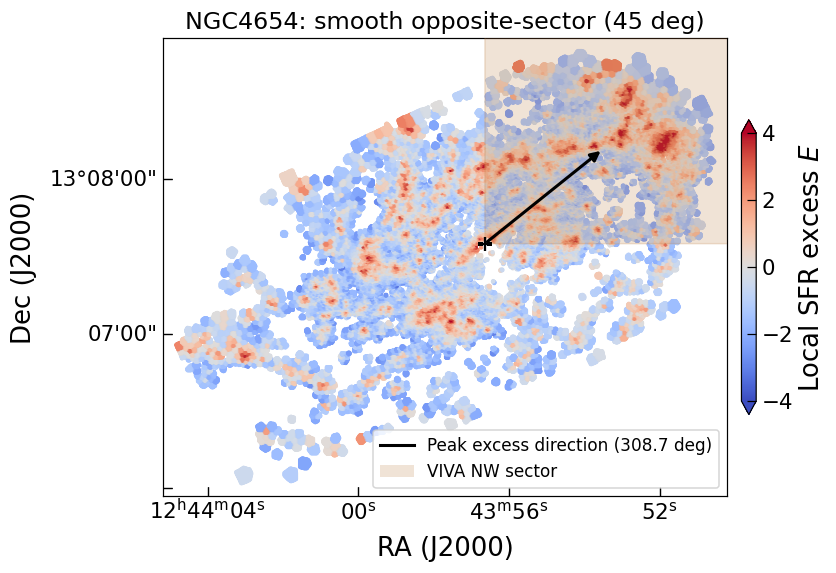

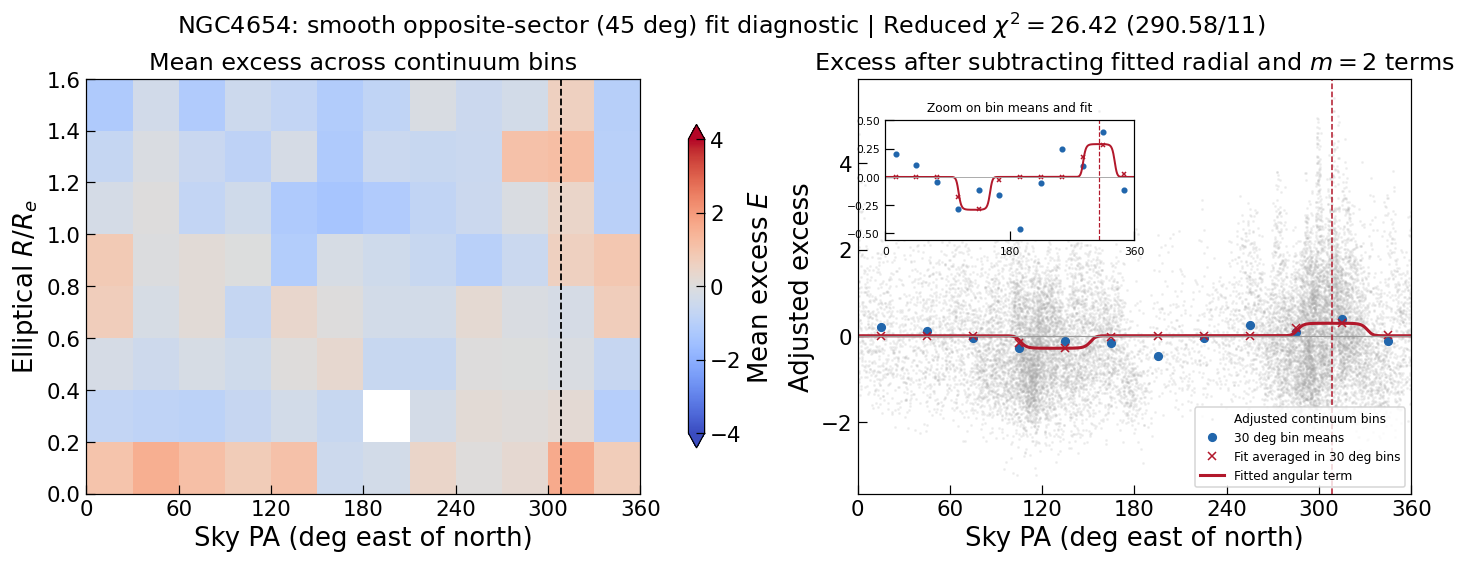

In [15]:
ngc4654_sector_row, ngc4654_sector_diagnostics = fit_ngc4654_localized(
    ngc4654_cosine_diagnostics, 'sector', width_deg=45.0, kappa=40.0)
sector_width_rows = [
    ngc4654_sector_row if width == 45 else
    fit_ngc4654_localized(ngc4654_cosine_diagnostics, 'sector', width, 40.0)[0]
    for width in (30.0, 45.0, 60.0, 90.0)
]
ngc4654_sector_width_check = pd.DataFrame(sector_width_rows).set_index('width_deg')
ngc4654_sector_width_check['PA_minus_primary_deg'] = (
    (ngc4654_sector_width_check.PA_deg - ngc4654_sector_row['PA_deg'] + 180) % 360 - 180)
display(ngc4654_sector_width_check.round(6))

ngc4654_sector_chi2 = plot_ngc4654_localized(
    ngc4654_sector_diagnostics, ngc4654_sector_row, 'sector',
    'NGC4654: smooth opposite-sector (45 deg)')

## Gaussian-like angular lobes with fixed 45° FWHM

$$
\begin{aligned}
\widehat E_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A\,\frac{\sinh[\kappa_{45}\cos(\phi_i-\theta)]}{\sinh\kappa_{45}}}_{\text{opposite-lobe term}}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

The 45° width enters through the fixed concentration
$$
\kappa_{45}=\frac{\ln 2}{1-\cos(45^\circ/2)}\simeq9.1059.
$$
The half-maximum points are approximately \(\theta\pm22.5^\circ\). This choice uses the near-peak exponential approximation to the normalized sinh profile. The fit varies the shared amplitude \(A\), sky PA \(\theta\), and annular coefficients with \(\kappa_{45}\) fixed.

The table reports wrapped PA shifts and in-sample RSS changes relative to the Fourier cosine. The narrow shapes are sensitivity checks for the fitted direction. The table and plots do not measure the significance of the new asymmetry terms or establish their physical origin.

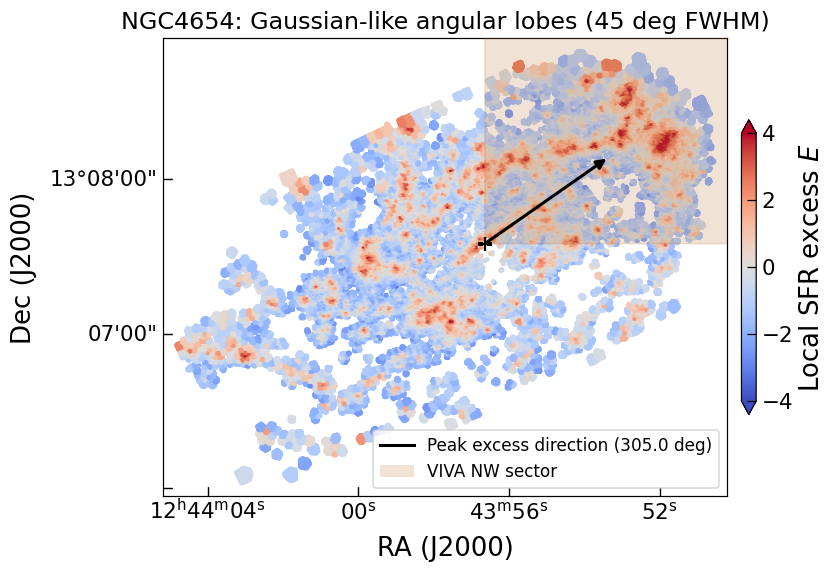

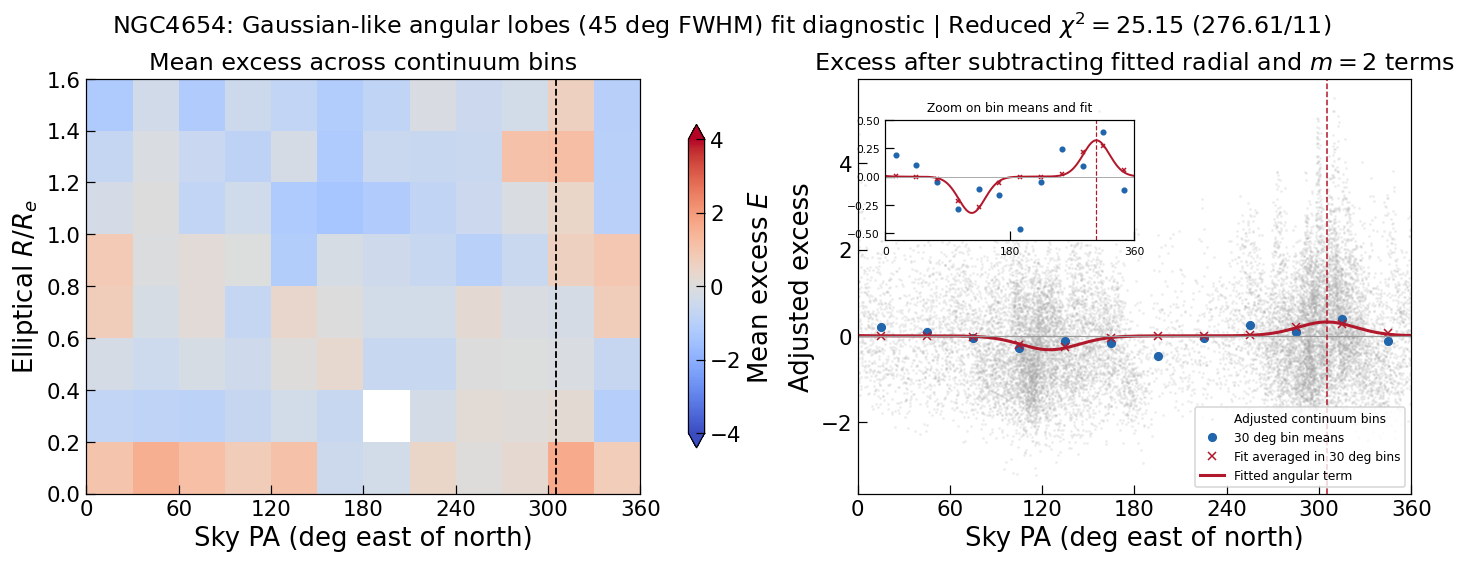

,PA_deg,amplitude_W,kappa,central_direction_contrast_W,RSS,RMSE_W,R2,N_BINID,width_deg,PA_minus_cosine_deg,RSS_reduction_vs_cosine_pct,angular_reduced_chi2
model,,,,,,,,,,,,
Fourier cosine,320.396471,0.233871,0.000000,0.467742,22115.883137,1.144463,0.129485,16885,NaN,0.000000,0.000000,24.817099
Smooth opposite-half,338.255022,0.200137,29.447423,0.400273,22086.824902,1.143711,0.130629,16885,NaN,17.858551,0.131391,22.985065
Smooth opposite-sector,308.702224,0.290203,40.000000,0.580406,22062.498493,1.143080,0.131586,16885,45.0,-11.694247,0.241386,26.416019
Gaussian-like angular lobes,304.951009,0.321882,9.105924,0.643765,22043.292664,1.142583,0.132342,16885,45.0,-15.445462,0.328228,25.146096


In [16]:
lobe_fwhm_deg = 45.0
lobe_kappa = np.log(2) / (1 - np.cos(np.deg2rad(lobe_fwhm_deg / 2)))
ngc4654_lobe_row, ngc4654_lobe_diagnostics = fit_ngc4654_localized(
    ngc4654_cosine_diagnostics, 'lobes', width_deg=lobe_fwhm_deg, kappa=lobe_kappa)
ngc4654_lobe_chi2 = plot_ngc4654_localized(
    ngc4654_lobe_diagnostics, ngc4654_lobe_row, 'lobes',
    'NGC4654: Gaussian-like angular lobes (45 deg FWHM)')

ngc4654_localized_comparison = pd.concat([
    ngc4654_angular_comparison.assign(N_BINID=ngc4654_angular_bin_count),
    pd.DataFrame([ngc4654_sector_row, ngc4654_lobe_row],
                 index=['Smooth opposite-sector', 'Gaussian-like angular lobes']),
]).rename_axis('model')
ngc4654_localized_comparison['PA_minus_cosine_deg'] = (
    (ngc4654_localized_comparison.PA_deg - cosine_row.PA_deg + 180) % 360 - 180)
ngc4654_localized_comparison['RSS_reduction_vs_cosine_pct'] = (
    100 * (1 - ngc4654_localized_comparison.RSS / cosine_row.RSS))
ngc4654_localized_comparison['angular_reduced_chi2'] = [
    item['reduced_chi2'] for item in (ngc4654_cosine_chi2, ngc4654_half_chi2,
                                    ngc4654_sector_chi2, ngc4654_lobe_chi2)
]
display(ngc4654_localized_comparison.round(6))

## Smooth opposite-sector fit with free total width

$$
\begin{aligned}
\widehat E_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A\,\frac{h_{\rm sec}(u_i;w,\kappa)}{h_{\rm sec}(1;w,\kappa)}}_{\text{opposite-sector term}}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

$$
\begin{aligned}
u_i &= \cos(\phi_i-\theta),\\
h_{\rm sec}(u;w,\kappa)
&=\tfrac12\left[
\tanh\!\bigl(\kappa[u-\cos(w/2)]\bigr)
-\tanh\!\bigl(\kappa[-u-\cos(w/2)]\bigr)
\right].
\end{aligned}
$$

The fit varies \(A\), \(\theta\), and \(w\), with \(5^\circ\le w\le180^\circ\) and \(\kappa=40\).

Fit the sky PA and total width per sector jointly, using the same unit-peak template and continuum bins as the 45° sector fit. Keep \(\kappa=40\) and allow a nominal width from 5° to 180°. The width sets the tanh transition threshold. The finite transition sharpness also affects the measured half-maximum width, especially for narrow sectors.

For these two free-width sections, the angular reduced \(\chi^2\) includes the local derivative with respect to width when the solution is interior. If the width reaches a bound, the diagnostic is conditional on that boundary width. Changes in RSS describe the in-sample effect of fitting one more parameter.

,PA_deg,amplitude_W,kappa,central_direction_contrast_W,RSS,RMSE_W,R2,width_deg,N_BINID,width_at_bound
Free-width opposite-sector,305.572857,0.417138,40.0,0.834277,21886.362062,1.138508,0.138519,27.514012,16885,False


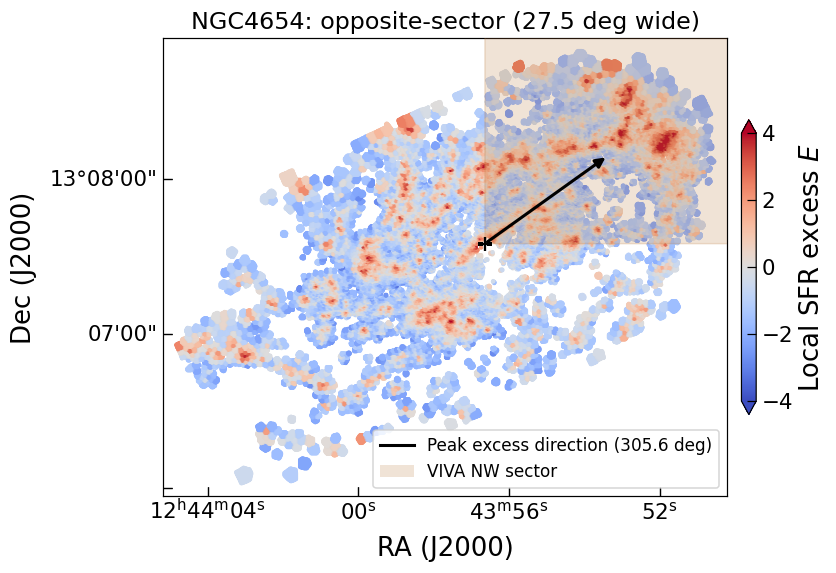

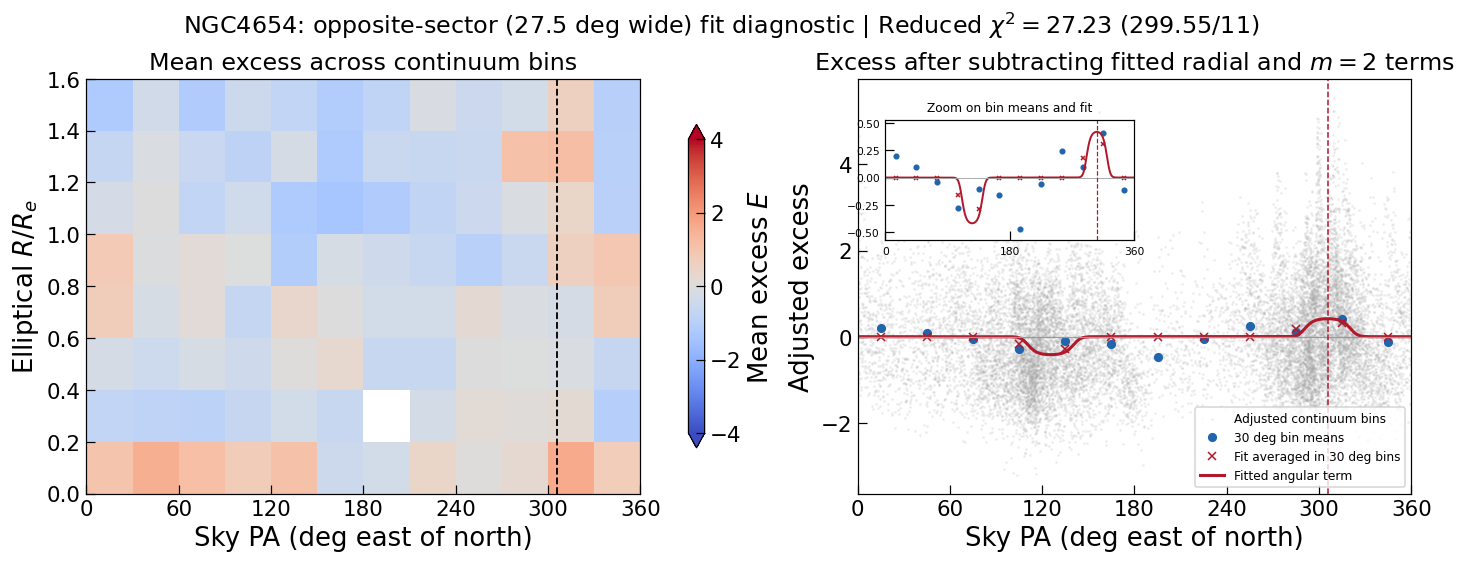

In [17]:
sector_free_bounds_deg = (5.0, 180.0)
ngc4654_free_sector_row, ngc4654_free_sector_diagnostics = fit_ngc4654_localized(
    ngc4654_cosine_diagnostics, 'sector', kappa=40.0, width_bounds=sector_free_bounds_deg)
display(pd.DataFrame([ngc4654_free_sector_row], index=['Free-width opposite-sector']).round(6))
ngc4654_free_sector_chi2 = plot_ngc4654_localized(
    ngc4654_free_sector_diagnostics, ngc4654_free_sector_row, 'sector',
    f"NGC4654: opposite-sector ({ngc4654_free_sector_row['width_deg']:.1f} deg wide)")

## Gaussian-like angular lobes with free FWHM

$$
\begin{aligned}
\widehat E_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A\,\frac{\sinh[\kappa(w)\cos(\phi_i-\theta)]}{\sinh\kappa(w)}}_{\text{opposite-lobe term}}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

At each trial FWHM \(w\), compute \(\kappa(w)\) from
$$
\frac{\sinh[\kappa(w)\cos(w/2)]}{\sinh\kappa(w)}=\frac12,
\qquad 5^\circ\le w\le120^\circ.
$$
At \(w=120^\circ\), use the cosine limit at \(\kappa=0\).

Fit \(A\), \(\theta\), and \(w\) jointly with the annular coefficients on the same bins. The trial width \(w\) changes the angular term through \(\kappa(w)\), evaluated at every trial width.

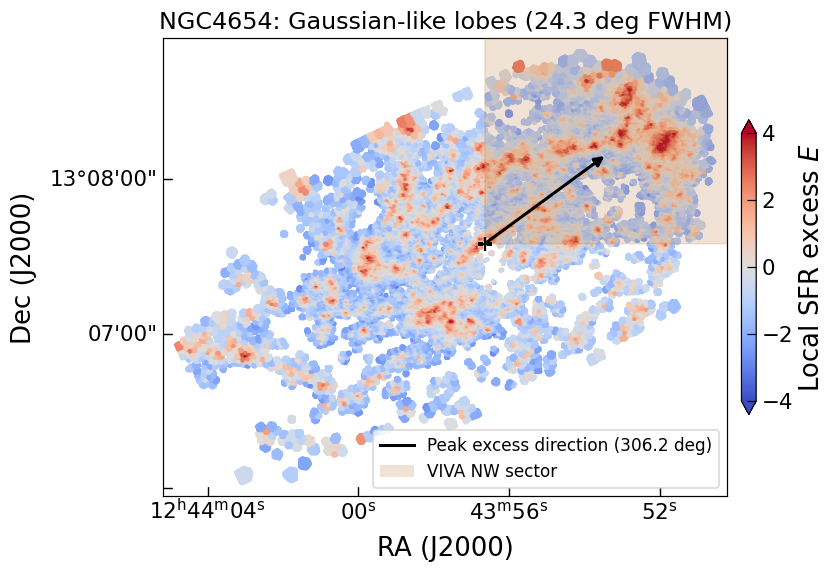

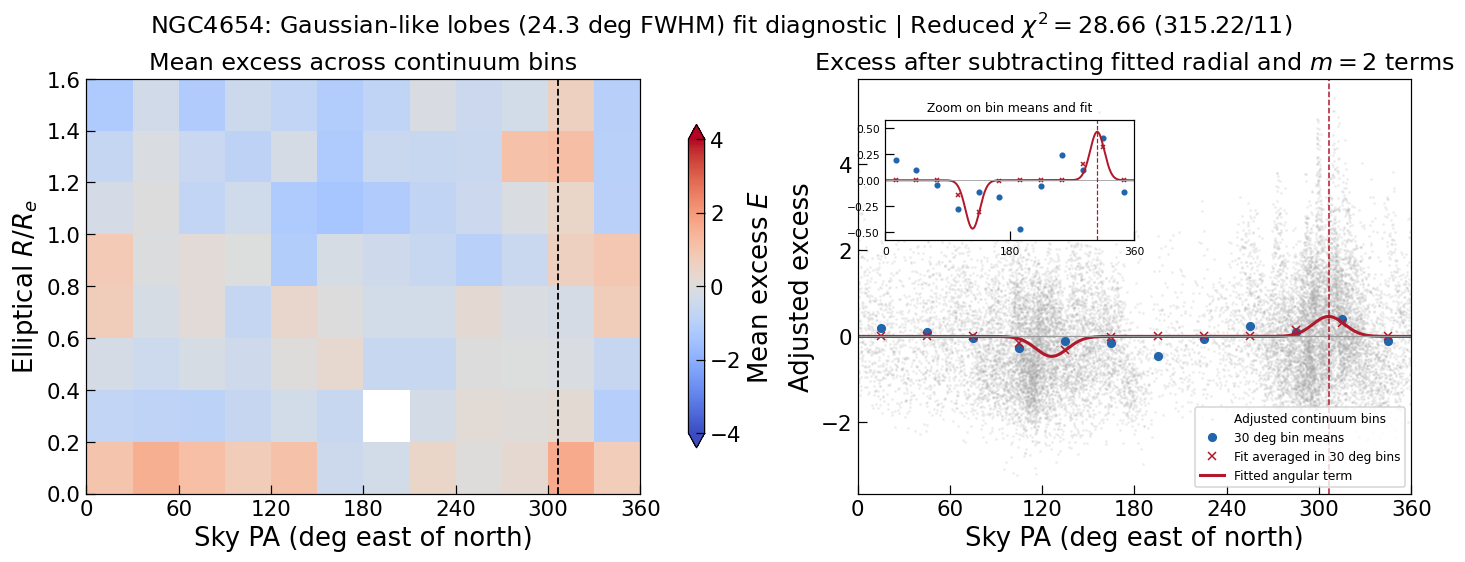

,PA_deg,amplitude_W,kappa,central_direction_contrast_W,RSS,RMSE_W,R2,N_BINID,width_deg,PA_minus_cosine_deg,RSS_reduction_vs_cosine_pct,angular_reduced_chi2,width_at_bound,width_definition
model,,,,,,,,,,,,,,
Fourier cosine,320.396471,0.233871,0.000000,0.467742,22115.883137,1.144463,0.129485,16885,NaN,0.000000,0.000000,24.817099,NaN,
Smooth opposite-half,338.255022,0.200137,29.447423,0.400273,22086.824902,1.143711,0.130629,16885,NaN,17.858551,0.131391,22.985065,NaN,
Smooth opposite-sector,308.702224,0.290203,40.000000,0.580406,22062.498493,1.143080,0.131586,16885,45.000000,-11.694247,0.241386,26.416019,NaN,Total sector width
Gaussian-like angular lobes,304.951009,0.321882,9.105924,0.643765,22043.292664,1.142583,0.132342,16885,45.000000,-15.445462,0.328228,25.146096,NaN,Lobe FWHM
Free-width opposite-sector,305.572857,0.417138,40.000000,0.834277,21886.362062,1.138508,0.138519,16885,27.514012,-14.823614,1.037811,27.231850,False,Total sector width
Free-FWHM Gaussian-like lobes,306.222922,0.464518,30.999326,0.929035,21925.316876,1.139521,0.136986,16885,24.278218,-14.173549,0.861671,28.656273,False,Lobe FWHM


In [18]:
lobe_free_bounds_deg = (5.0, 120.0)
ngc4654_free_lobe_row, ngc4654_free_lobe_diagnostics = fit_ngc4654_localized(
    ngc4654_cosine_diagnostics, 'lobes', width_bounds=lobe_free_bounds_deg)
ngc4654_free_lobe_chi2 = plot_ngc4654_localized(
    ngc4654_free_lobe_diagnostics, ngc4654_free_lobe_row, 'lobes',
    f"NGC4654: Gaussian-like lobes ({ngc4654_free_lobe_row['width_deg']:.1f} deg FWHM)")

free_rows = pd.DataFrame([ngc4654_free_sector_row, ngc4654_free_lobe_row],
                         index=['Free-width opposite-sector', 'Free-FWHM Gaussian-like lobes'])
free_rows['angular_reduced_chi2'] = [ngc4654_free_sector_chi2['reduced_chi2'],
                                    ngc4654_free_lobe_chi2['reduced_chi2']]
ngc4654_free_width_comparison = pd.concat([
    ngc4654_localized_comparison, free_rows,
]).rename_axis('model')
ngc4654_free_width_comparison['width_definition'] = [
    '', '', 'Total sector width', 'Lobe FWHM', 'Total sector width', 'Lobe FWHM',
]
ngc4654_free_width_comparison['PA_minus_cosine_deg'] = (
    (ngc4654_free_width_comparison.PA_deg - cosine_row.PA_deg + 180) % 360 - 180)
ngc4654_free_width_comparison['RSS_reduction_vs_cosine_pct'] = (
    100 * (1 - ngc4654_free_width_comparison.RSS / cosine_row.RSS))
display(ngc4654_free_width_comparison.round(6))